In [1]:
import numpyro
numpyro.set_host_device_count(4)  # run the 4 MCMC chains in parallel; must happen before JAX starts
import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)  # double precision: we invert covariance matrices below

import numpy as np
import matplotlib.pyplot as plt
import corner
import numpyro.distributions as dist
from numpyro import infer
from numpyro.diagnostics import effective_sample_size

plt.style.use("bayesian_stats_course_tools.light")

# Week 11 Exercises: fitting the hyperparameters of Bayesian linear regression

In the weight-space explorer, the posterior over the weights is always computed for **fixed** hyperparameters $\sigma_w$ and $\beta$: whatever the sliders say. Here we treat them as unknowns and sample them, keeping the number of basis functions fixed at $M = 20$ and the noise level known, $\sigma_n = 0.15$.

The model, in the notation of the lecture (Rasmussen & Williams; $\Phi$ has one **column** $\phi(x_i)$ per data point):

$$f(x) = \sum_{j=0}^{M-1} w_j P_j(x) = \phi(x)^\top w, \qquad y = \Phi^\top w + \varepsilon, \qquad \varepsilon \sim \mathcal N_\varepsilon(0, \sigma_n^2 I)$$

$$w \sim \mathcal N_w\big(0, \Sigma_p\big), \qquad (\Sigma_p)_{jj} = \sigma_w^2\,(j+1)^{-\beta}$$

$$\ln \sigma_w \sim \mathcal U(\ln 0.05, \ln 5), \qquad \beta \sim \mathcal U(0, 6)$$

The prior ranges are the same as the explorer's sliders, so any posterior sample is a setting you can dial into the explorer.

**Data.** The files in `../lectures/data/gp_legendre/` are *identical* to what the explorer generates (seed 7, $\sigma_{\rm true} = 0.15$):

| file | explorer settings |
|---|---|
| `sin3x_n15.txt` | Truth sin(3x), $n = 15$ (the explorer's default) |
| `chirp_n40.txt` | Truth Chirp sin(6x²), $n = 40$ |

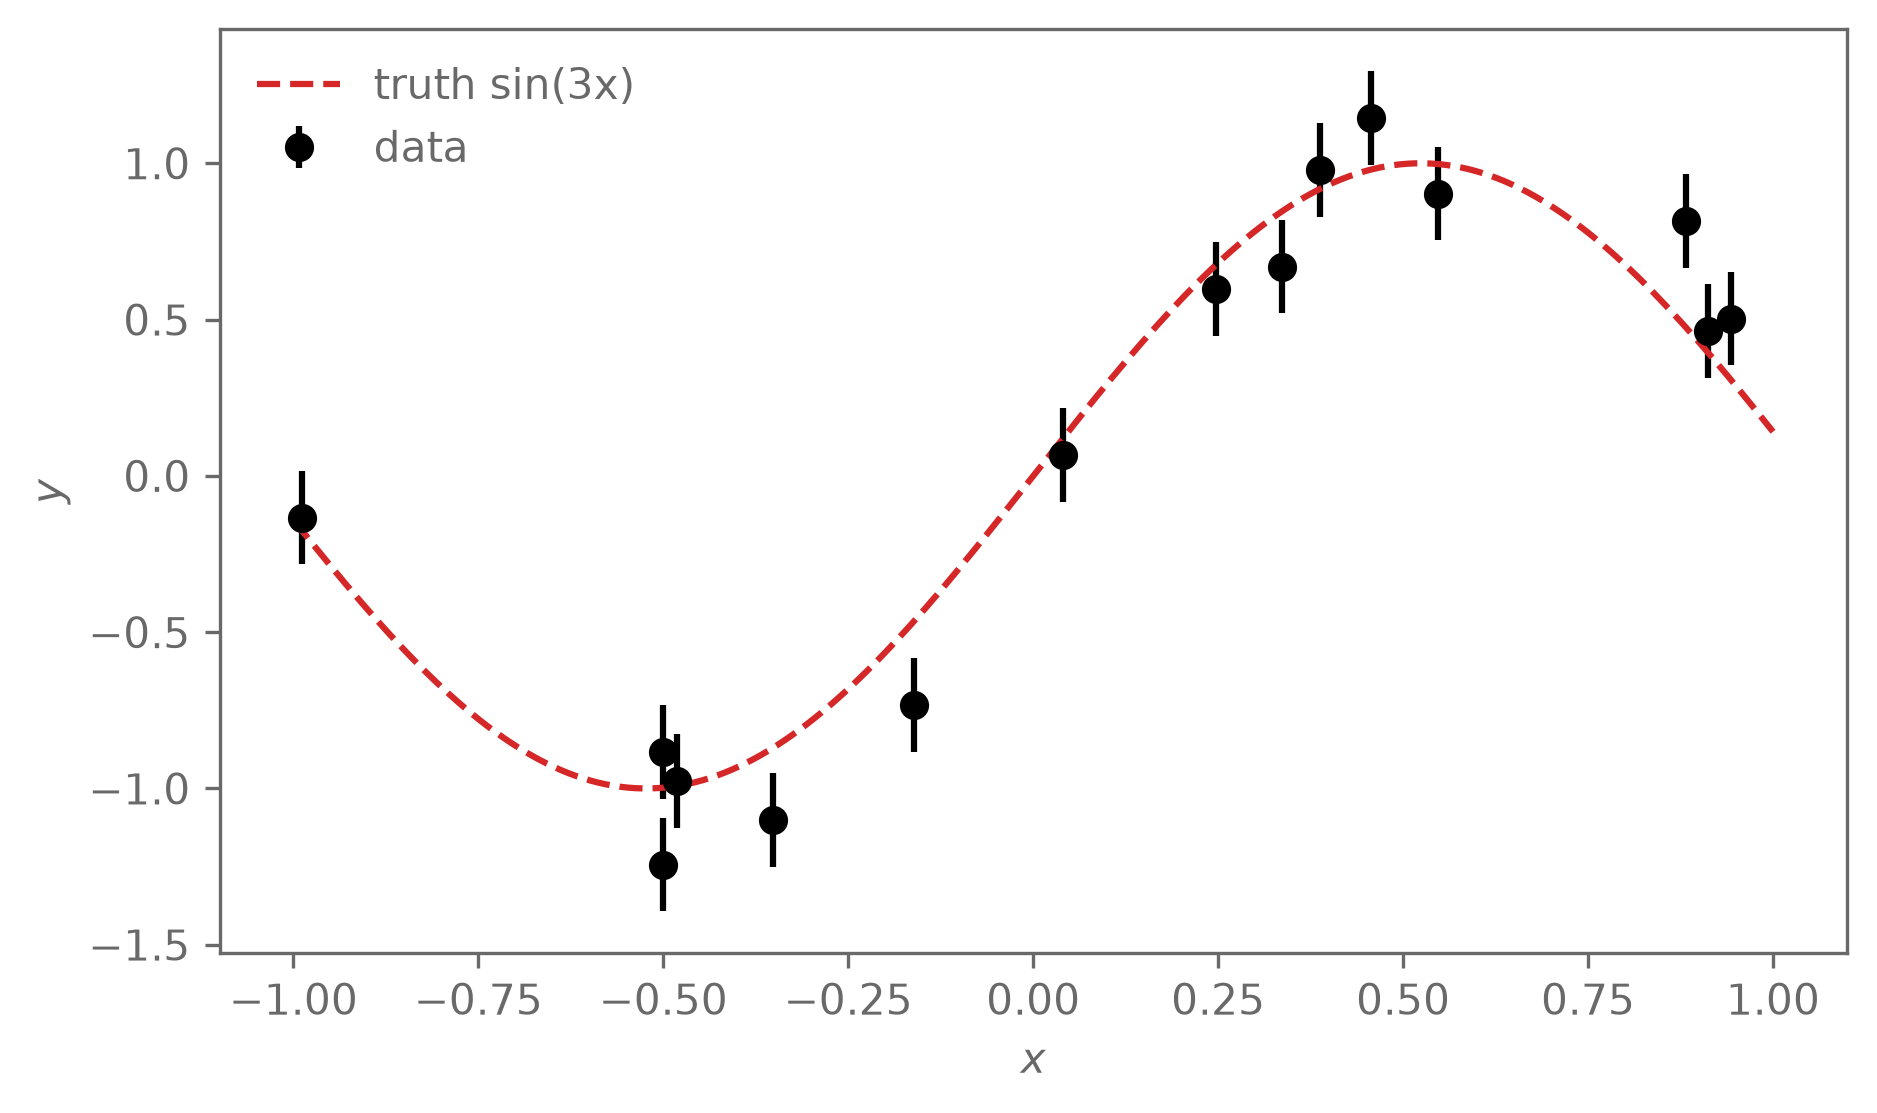

In [2]:
# Notation
#   n_basis    number of Legendre basis functions M (fixed at 20)
#   n_data     number of data points
#   n_test     number of x positions we predict at
#   n_samples  number of posterior samples (all chains together)
N_BASIS = 20
SIGMA_NOISE = 0.15                                  # sigma_n, treated as known
LOG_SIGMA_W_RANGE = (np.log(0.05), np.log(5.0))     # prior range of ln(sigma_w)
BETA_RANGE = (0.0, 6.0)                             # prior range of beta
DATA_DIRECTORY = "../lectures/data/gp_legendre"

# load the default data (15 noisy points of sin(3x)) and a grid of x values to predict at
x_data, y_data = np.loadtxt(f"{DATA_DIRECTORY}/sin3x_n15.txt", unpack=True)  # each (n_data,)
x_test = np.linspace(-1, 1, 200)                                              # (n_test,)

# plot the data and the true function
plt.errorbar(x_data, y_data, SIGMA_NOISE, fmt="o", color="k", label="data")
plt.plot(x_test, np.sin(3 * x_test), "--", color="C3", label="truth sin(3x)")
plt.xlabel("$x$"); plt.ylabel("$y$"); plt.legend();

In [3]:
def legendre_features(positions, n_basis):
    """Feature matrix Phi with one COLUMN per input (Rasmussen & Williams convention).

    positions: (n_points,) -> returns (n_basis, n_points); row j is P_j(x). A scalar gives (n_basis,).
    Uses the recursion (j+1) P_{j+1} = (2j+1) x P_j - j P_{j-1}.
    """
    # start from P_0 = 1 and P_1 = x, then build each higher degree from the two below it
    rows = [jnp.ones_like(positions), positions]
    for degree in range(1, n_basis - 1):
        rows.append(((2 * degree + 1) * positions * rows[degree] - degree * rows[degree - 1]) / (degree + 1))
    return jnp.stack(rows[:n_basis])


def prior_variances(sigma_w, beta, n_basis):
    """Diagonal of Sigma_p: (Sigma_p)_jj = sigma_w^2 (j+1)^(-beta). Shape (n_basis,)."""
    return sigma_w**2 * jnp.arange(1, n_basis + 1) ** (-beta)


def sample_hyperparameters():
    """Priors on sigma_w (log-uniform) and beta (uniform): the explorer's slider ranges."""
    # sample ln(sigma_w), so its prior is log-uniform; record sigma_w itself as a deterministic
    log_sigma_w = numpyro.sample("log_sigma_w", dist.Uniform(*LOG_SIGMA_W_RANGE))
    beta = numpyro.sample("beta", dist.Uniform(*BETA_RANGE))
    sigma_w = numpyro.deterministic("sigma_w", jnp.exp(log_sigma_w))
    return sigma_w, beta


def run_nuts(model, *model_args, target_accept=0.8, n_warmup=1000, n_samples_per_chain=1000, seed=0):
    """Run 4 NUTS chains; print the number of divergences and, if the model has one, the effective sample size (ESS) of beta."""
    # set up and run 4 NUTS chains, keeping track of which transitions diverged
    mcmc = infer.MCMC(infer.NUTS(model, target_accept_prob=target_accept), num_warmup=n_warmup,
                      num_samples=n_samples_per_chain, num_chains=4, progress_bar=False)
    mcmc.run(jax.random.key(seed), *model_args, extra_fields=("diverging",))
    # count the divergences, and compute the effective sample size of beta if the model has one
    n_divergent = int(mcmc.get_extra_fields()["diverging"].sum())
    samples_by_chain = mcmc.get_samples(group_by_chain=True)
    if "beta" in samples_by_chain:
        ess_beta = float(effective_sample_size(np.asarray(samples_by_chain["beta"])))
        print(f"divergences: {n_divergent},  ESS(beta): {ess_beta:.0f}")
    else:
        print(f"divergences: {n_divergent}")
    return mcmc


def plot_hyperparameter_posteriors(sample_sets, labels):
    """Overlay corner plots of (sigma_w, beta) for several runs. sample_sets: list of mcmc.get_samples()."""
    # draw each run's corner plot on top of the previous one, in a new color
    figure = None
    for index, (samples, label) in enumerate(zip(sample_sets, labels)):
        points = np.column_stack([np.log10(samples["sigma_w"]), samples["beta"]])
        figure = corner.corner(points, fig=figure, color=f"C{index}", bins=30, smooth=1.0,
                               labels=[r"$\log_{10}\sigma_w$", r"$\beta$"],
                               range=[(np.log10(0.05), np.log10(5.0)), BETA_RANGE],
                               plot_datapoints=False, plot_density=False, hist_kwargs={"density": True})
    # one legend entry per run
    figure.legend([plt.Line2D([], [], color=f"C{index}") for index in range(len(labels))], labels, loc="upper right")
    return figure

In [4]:
# Phi depends only on the inputs, so compute it once here rather than inside the models:
# a numpyro model is re-evaluated at every step of the sampler.
features = legendre_features(x_data, N_BASIS)        # Phi:   (n_basis, n_data)
features_test = legendre_features(x_test, N_BASIS)   # Phi_*: (n_basis, n_test)

# Exercise 1: sampling $\sigma_w$ and $\beta$ with $M = 20$ fixed

## Part A: weight space

Sample the weights and the hyperparameters **jointly**. This is a hierarchical model: the hyperparameters set the prior width of every weight.

$$w \sim \mathcal N_w\big(0, \Sigma_p(\sigma_w, \beta)\big), \qquad y \sim \mathcal N_y\big(\Phi^\top w,\ \sigma_n^2 I\big)$$

1. Complete `centered_model` below. It takes the precomputed feature matrix `features` ($\Phi$).
2. Run it with `run_nuts(centered_model, features, y_data)`. How many divergences do you get?
3. Plot the posterior of $(\sigma_w, \beta)$ with `plot_hyperparameter_posteriors`. Take the posterior medians of $\sigma_w$ and $\beta$ (`np.median`) and put them into the weight-space explorer (Truth sin(3x), $n = 15$, $M = 20$, $\sigma_n = 0.15$). Does the explorer's posterior look like a good fit?
4. Plot the **model posterior predictive** (the function $f$, no noise) with **the recipe** (slide "Predictions: the recipe"): for a few hundred posterior samples $w^{(s)}$, evaluate $f_*^{(s)} = \Phi_*^\top w^{(s)}$ with `features_test`, and plot the draws (or their mean and a band) together with the data.
5. **The weights.** Remake the *Weights* panel of the weight-space explorer from your samples: plot the posterior of each weight $w_j$ against its degree $j$ with `plt.violinplot`. If you have time, add the prior on the weights to the same plot, using the posterior on $(\sigma_w, \beta)$: for each posterior sample, draw $w_j \sim \mathcal N(0, s_j^2)$ with $s_j^2 = \sigma_w^2 (j+1)^{-\beta}$ (`prior_variances`). Which weights do the data pin down, and which are still set by the prior?

In [5]:
def centered_model(features, y_data):
    sigma_w, beta = sample_hyperparameters()
    # prior standard deviation of each weight, then sample the weights themselves
    weight_scales = jnp.sqrt(prior_variances(sigma_w, beta, N_BASIS))           # (n_basis,)
    weights = numpyro.sample("weights", dist.Normal(0.0, weight_scales))        # (n_basis,)
    # likelihood: the data are the function Phi^T w plus Gaussian noise
    numpyro.sample("y", dist.Normal(features.T @ weights, SIGMA_NOISE), obs=y_data)

divergences: 0,  ESS(beta): 378
posterior medians: sigma_w = 2.15  beta = 2.12


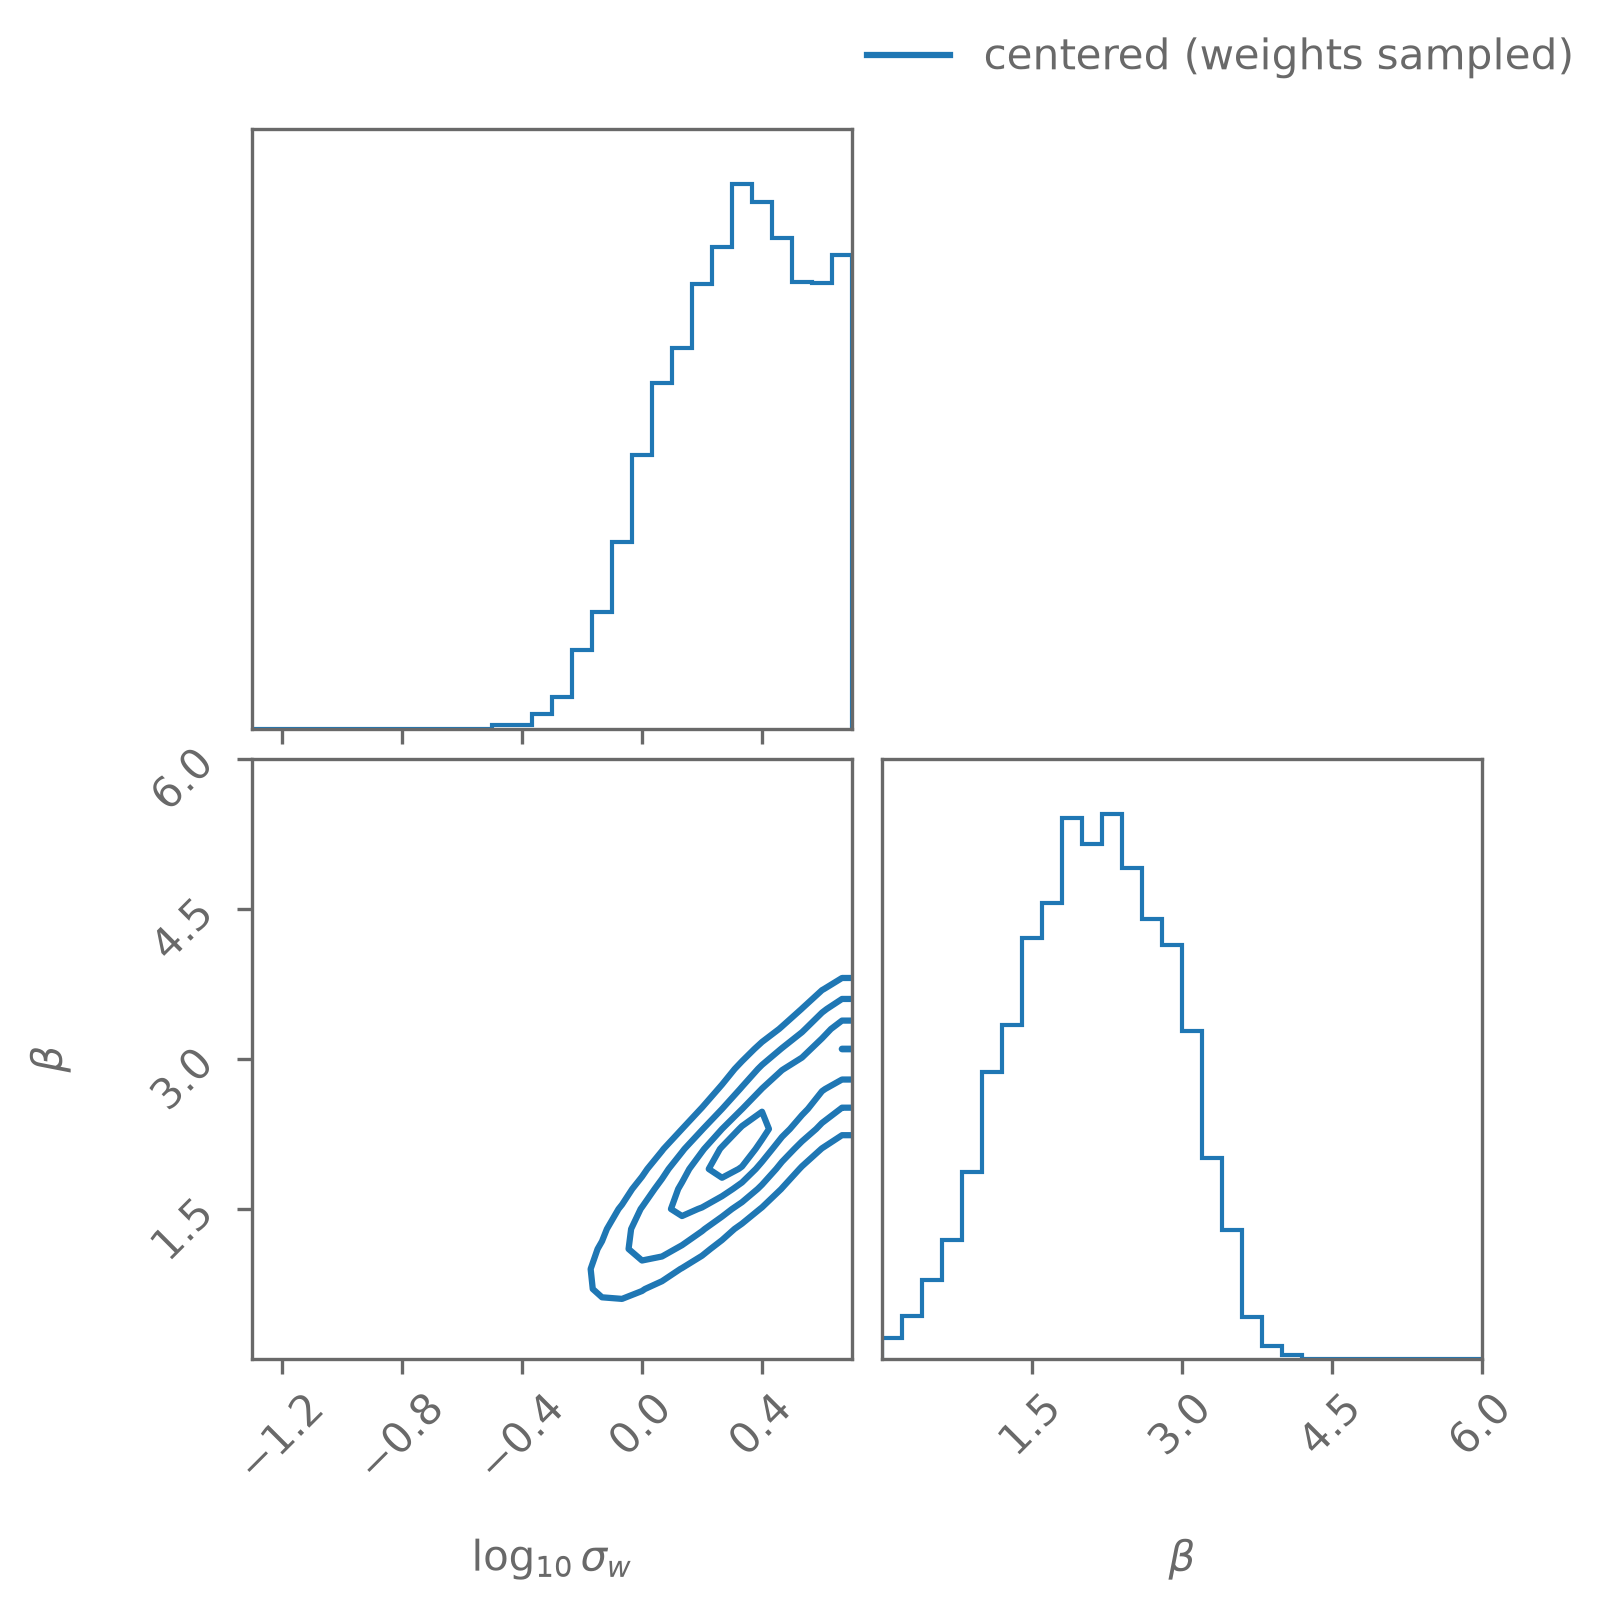

In [6]:
# sample Part A's model and look at the (sigma_w, beta) posterior
mcmc_centered = run_nuts(centered_model, features, y_data)
samples_centered = mcmc_centered.get_samples()
plot_hyperparameter_posteriors([samples_centered], ["centered (weights sampled)"]);
# posterior medians, to dial into the explorer
print("posterior medians: sigma_w =", np.median(samples_centered["sigma_w"]).round(2),
      " beta =", np.median(samples_centered["beta"]).round(2))

*Solution note.* No divergences on these data (ESS of $\beta$ about 380 out of 4000): with 15 points and 20 weights the funnel is mild. With fewer or noisier data, or more weights, it gets worse (slide "Watch out: funnels"). The posterior medians are $\sigma_w \approx 2.2$ and $\beta \approx 2.1$; with these in the explorer, the posterior mean follows sin(3x) closely inside the data. The posterior on $\sigma_w$ is broad and reaches the prior's upper edge, $\sigma_w = 5$: the data constrain $\sigma_w$ and $\beta$ together more than either one alone.

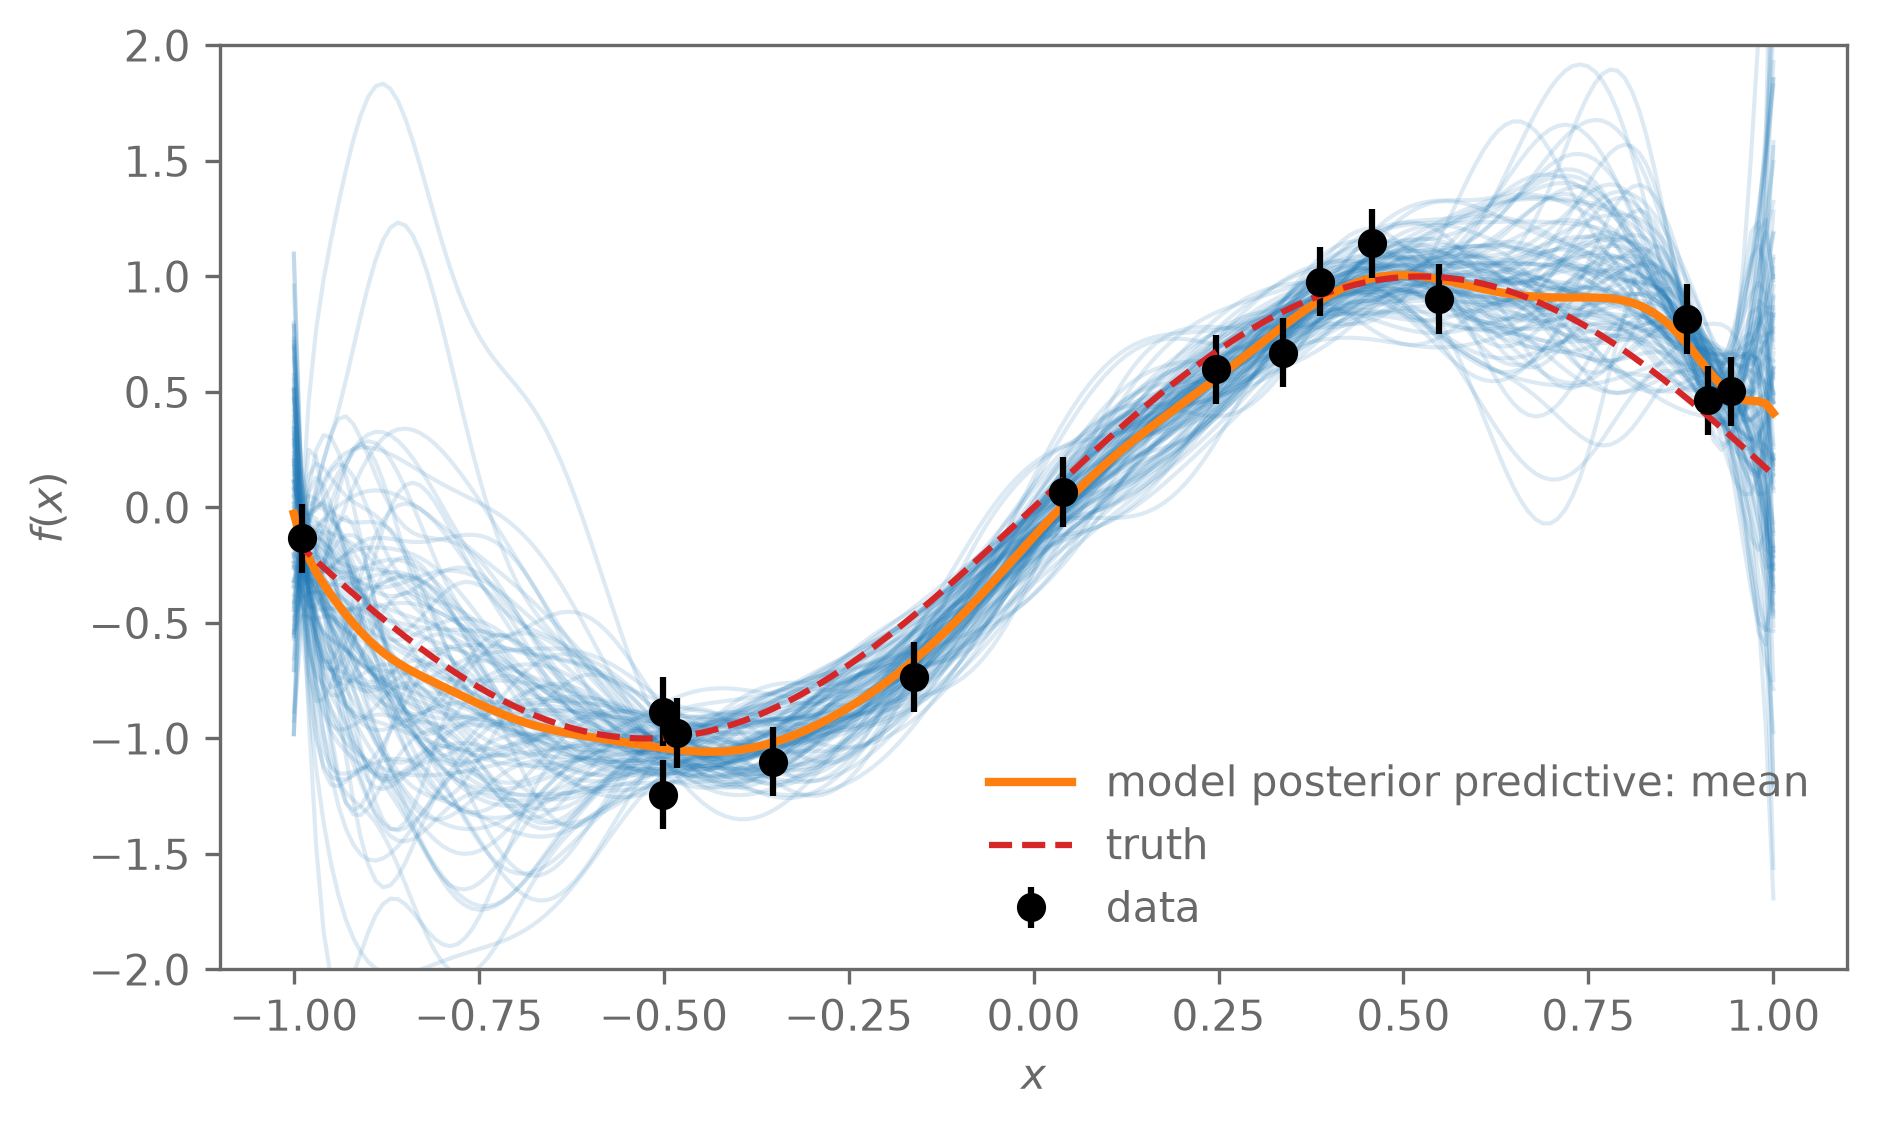

In [7]:
# each posterior sample of the weights gives one function at the test points
function_draws = np.asarray(samples_centered["weights"] @ features_test)  # (n_samples, n_test)

# plot every 40th draw, their mean, the data and the truth
plt.plot(x_test, function_draws[::40].T, color="C0", alpha=0.15, lw=1)
plt.plot(x_test, function_draws.mean(axis=0), color="C1", lw=2, label="model posterior predictive: mean")
plt.errorbar(x_data, y_data, SIGMA_NOISE, fmt="o", color="k", label="data")
plt.plot(x_test, np.sin(3 * x_test), "--", color="C3", label="truth")
plt.ylim(-2, 2); plt.xlabel("$x$"); plt.ylabel("$f(x)$"); plt.legend();

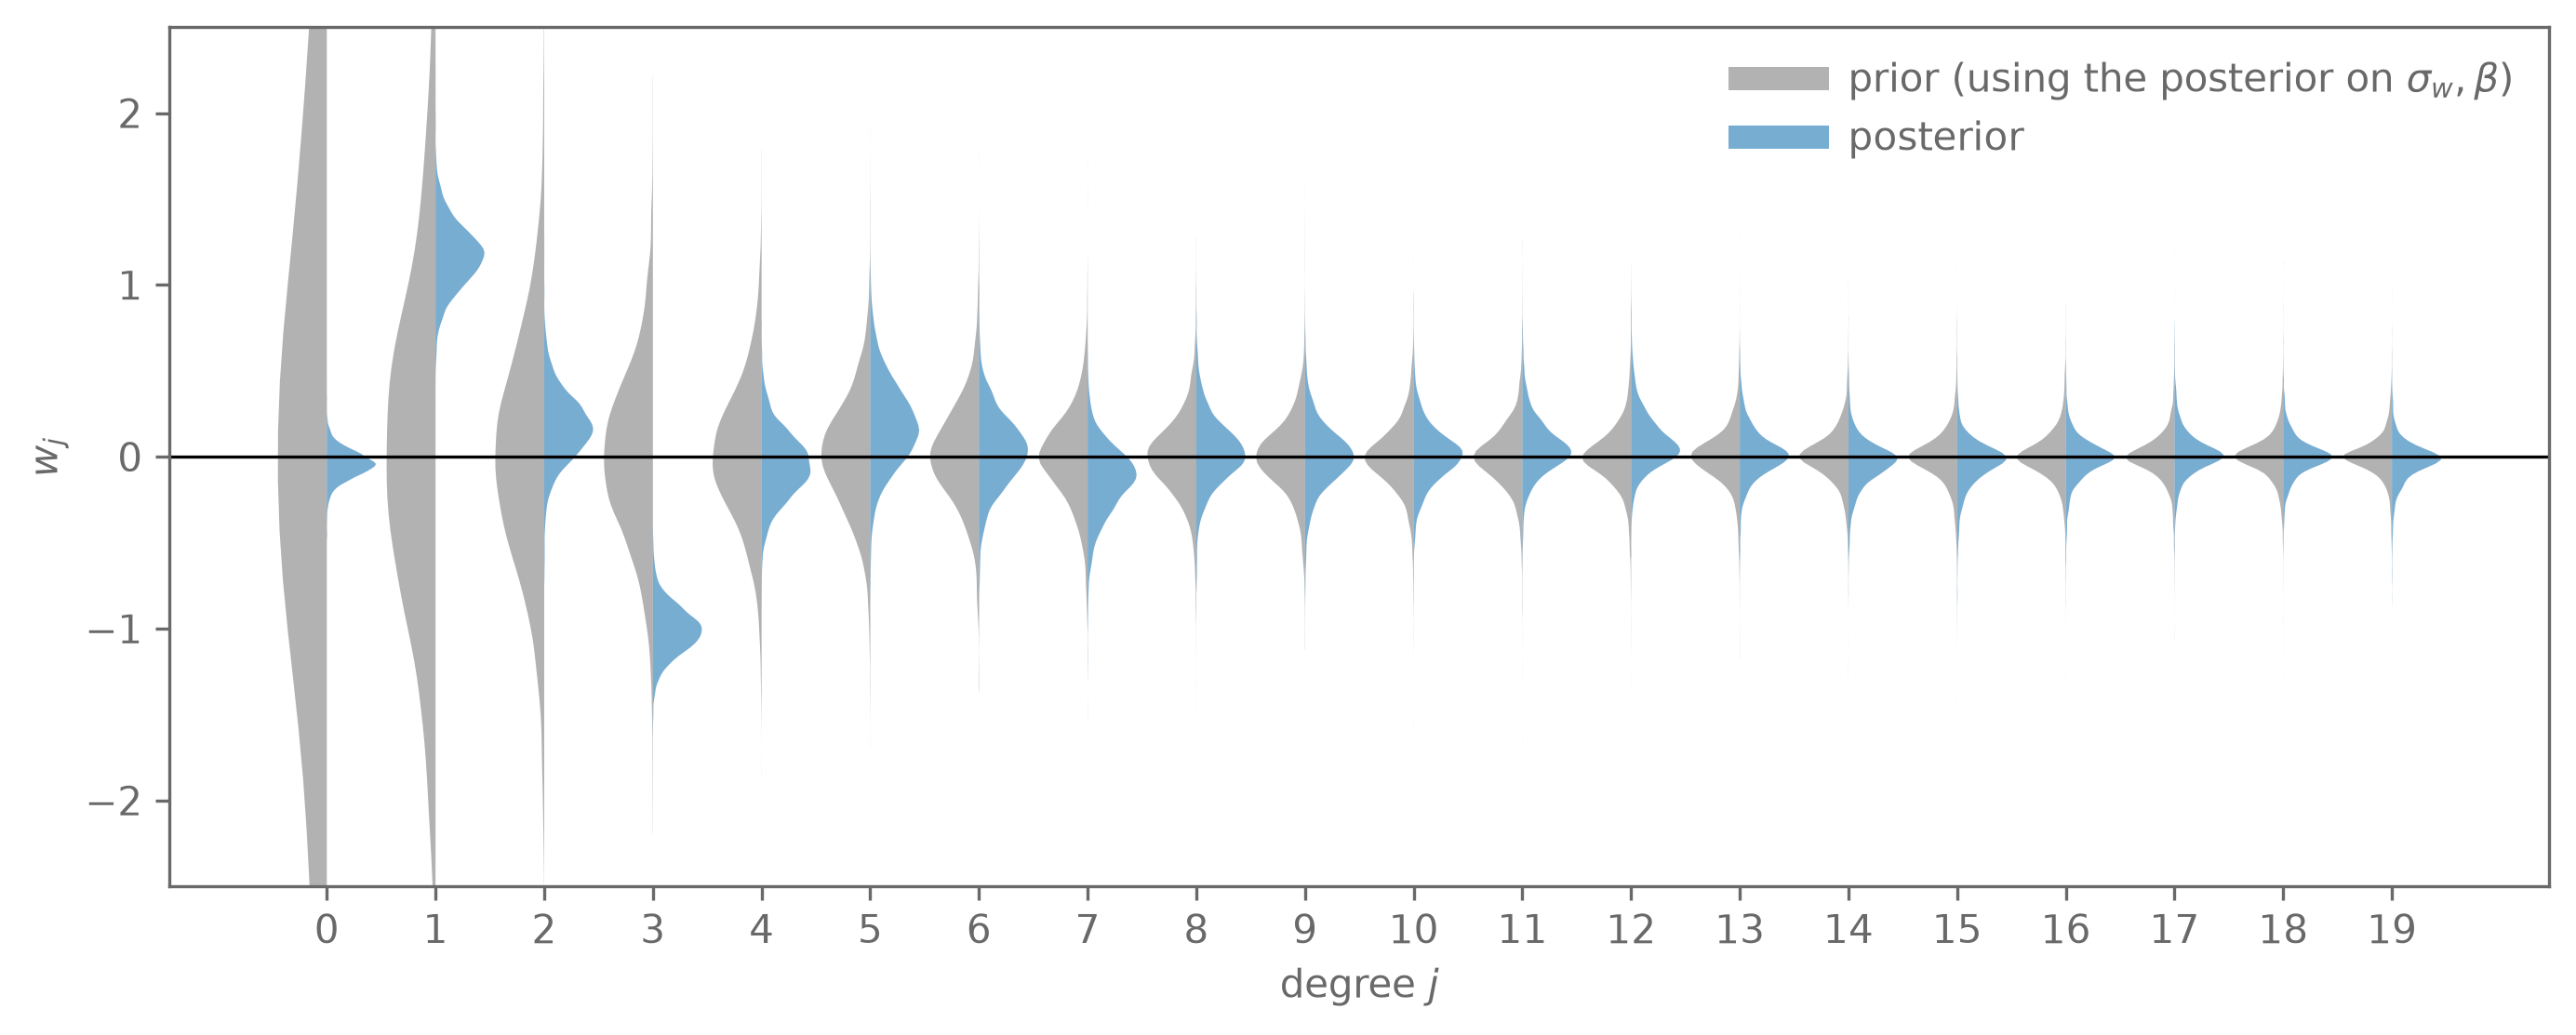

In [8]:
# the prior on the weights, using the posterior on (sigma_w, beta): one draw of w per posterior sample
weight_random = np.random.default_rng(0)
prior_scales = np.sqrt(np.asarray(prior_variances(samples_centered["sigma_w"][:, None], samples_centered["beta"][:, None], N_BASIS)))
prior_weight_draws = prior_scales * weight_random.normal(size=prior_scales.shape)          # (n_samples, n_basis)
posterior_weight_draws = np.asarray(samples_centered["weights"])                           # (n_samples, n_basis)

# split violins: the prior on the left of each degree, the posterior on the right
degrees = np.arange(N_BASIS)
figure, axis = plt.subplots(figsize=(11, 4))
for draws, side, color, label in [(prior_weight_draws, "low", "C7", "prior (using the posterior on $\\sigma_w, \\beta$)"),
                                   (posterior_weight_draws, "high", "C0", "posterior")]:
    parts = axis.violinplot(draws, positions=degrees, side=side, showextrema=False, widths=0.9)
    for body in parts["bodies"]: body.set_facecolor(color); body.set_alpha(0.6)
    axis.plot([], [], color=color, lw=6, alpha=0.6, label=label)
axis.axhline(0, color="k", lw=0.8)
axis.set_ylim(-2.5, 2.5)   # the prior on w_0 has long tails; zoom in on the rest
axis.set_xticks(degrees); axis.set_xlabel("degree $j$"); axis.set_ylabel("$w_j$"); axis.legend();

*Solution note.* The data pin down the lowest degrees: for $j \le 3$ the posterior is 3–30% as wide as the prior, and $w_1$ and $w_3$ are clearly away from zero (sin 3x is odd, so it is built mostly from odd degrees). From about degree 5 on, the posterior is still 75–100% as wide as the prior: 15 noisy points say little about those weights, and what keeps them small is the prior's $(j+1)^{-\beta}$ decay.

## Part B: integrate out the weights

The weights can be integrated out analytically (slide "Evidence"):

$$p(y \mid X, \sigma_w, \beta) = \mathcal N_y\big(0,\ C\big), \qquad C = \Phi^\top \Sigma_p \Phi + \sigma_n^2 I.$$

Now the sampler only sees the two hyperparameters.

1. Complete `marginal_model`: build $C$ yourself and use `dist.MultivariateNormal` as the likelihood.
2. Record the **model predictions** inside the model with `numpyro.deterministic`. They are not sampled: for fixed $(\sigma_w, \beta)$ the posterior over the weights is Gaussian, $\mathcal N_w(\mu_w, \Sigma_w)$ (slide "Posterior over the weights"), so the prediction at `x_test` is Gaussian too, with mean $\Phi_*^\top \mu_w$ and variance $\operatorname{diag}(\Phi_*^\top \Sigma_w \Phi_*)$ (slide "Predictions: closed form").
3. Sample it and compare the $(\sigma_w, \beta)$ posterior with Part A. Should they agree? Why?
4. Plot the **model posterior predictive** for $f$. Each hyperparameter sample $s$ gives a Gaussian with mean $m^{(s)}(x)$ and variance $v^{(s)}(x)$; averaging over samples, the total variance is $\operatorname{Var}[f(x) \mid y] = \operatorname{E}_s\big[v^{(s)}(x)\big] + \operatorname{Var}_s\big[m^{(s)}(x)\big]$ (law of total variance). Compare with Part A. Then add the noise, $+\sigma_n^2$, to get the **posterior predictive** for new data $y_*$, and plot that band too.

In [9]:
def marginal_model(features, y_data, features_test):
    sigma_w, beta = sample_hyperparameters()
    variances = prior_variances(sigma_w, beta, N_BASIS)   # diagonal of Sigma_p: (n_basis,)
    n_data = features.shape[1]

    # Marginal covariance of the data, C = Phi^T Sigma_p Phi + sigma_n^2 I: the weights are integrated out
    covariance = features.T @ (variances[:, None] * features) + SIGMA_NOISE**2 * jnp.eye(n_data)  # (n_data, n_data)
    numpyro.sample("y", dist.MultivariateNormal(jnp.zeros(n_data), covariance), obs=y_data)

    # model predictions at x_test, in closed form: record their mean and variance (item 2)
    posterior_precision = features @ features.T / SIGMA_NOISE**2 + jnp.diag(1.0 / variances)   # Sigma_w^{-1}: (n_basis, n_basis)
    posterior_covariance = jnp.linalg.inv(posterior_precision)                                   # Sigma_w
    posterior_mean = posterior_covariance @ features @ y_data / SIGMA_NOISE**2                   # mu_w: (n_basis,)
    numpyro.deterministic("f_test_mean", features_test.T @ posterior_mean)                       # (n_test,)
    numpyro.deterministic("f_test_var", jnp.sum(features_test * (posterior_covariance @ features_test), axis=0))  # (n_test,)

divergences: 0,  ESS(beta): 734


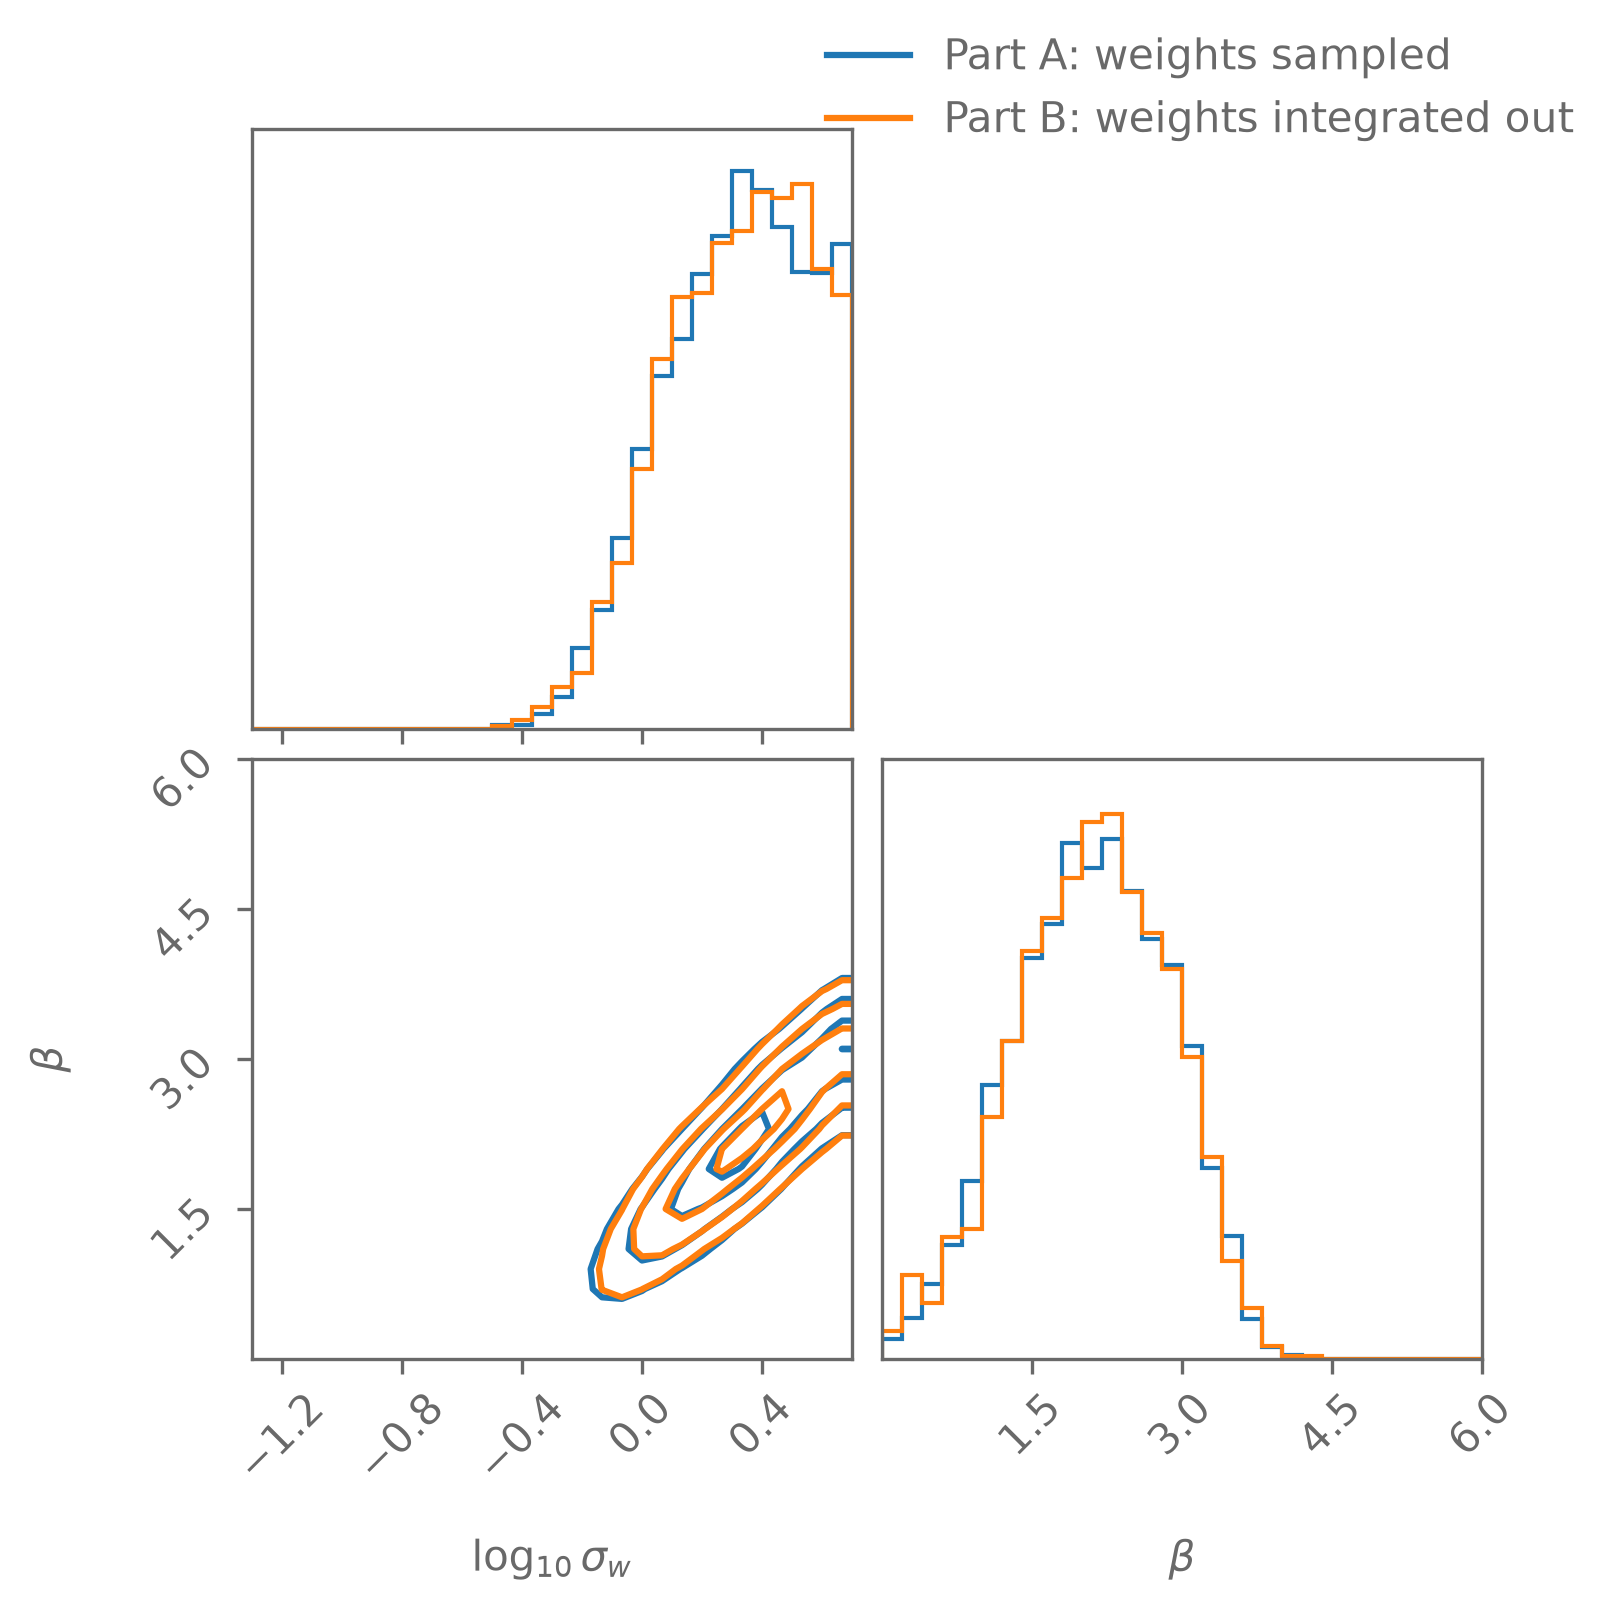

In [10]:
# sample Part B's model and compare its (sigma_w, beta) posterior with Part A's
mcmc_marginal = run_nuts(marginal_model, features, y_data, features_test)
samples_marginal = mcmc_marginal.get_samples()
plot_hyperparameter_posteriors([samples_centered, samples_marginal],
                               ["Part A: weights sampled", "Part B: weights integrated out"]);

*Solution note.* The two posteriors agree: both models have exactly the same joint distribution of $(w, \sigma_w, \beta, y)$. Part A integrates out $w$ numerically (by sampling it and ignoring it), Part B analytically. Part B also mixes about twice as well (ESS of $\beta$ about 730 against 380), because the sampler no longer has to move the 20 weights with the hyperparameters.

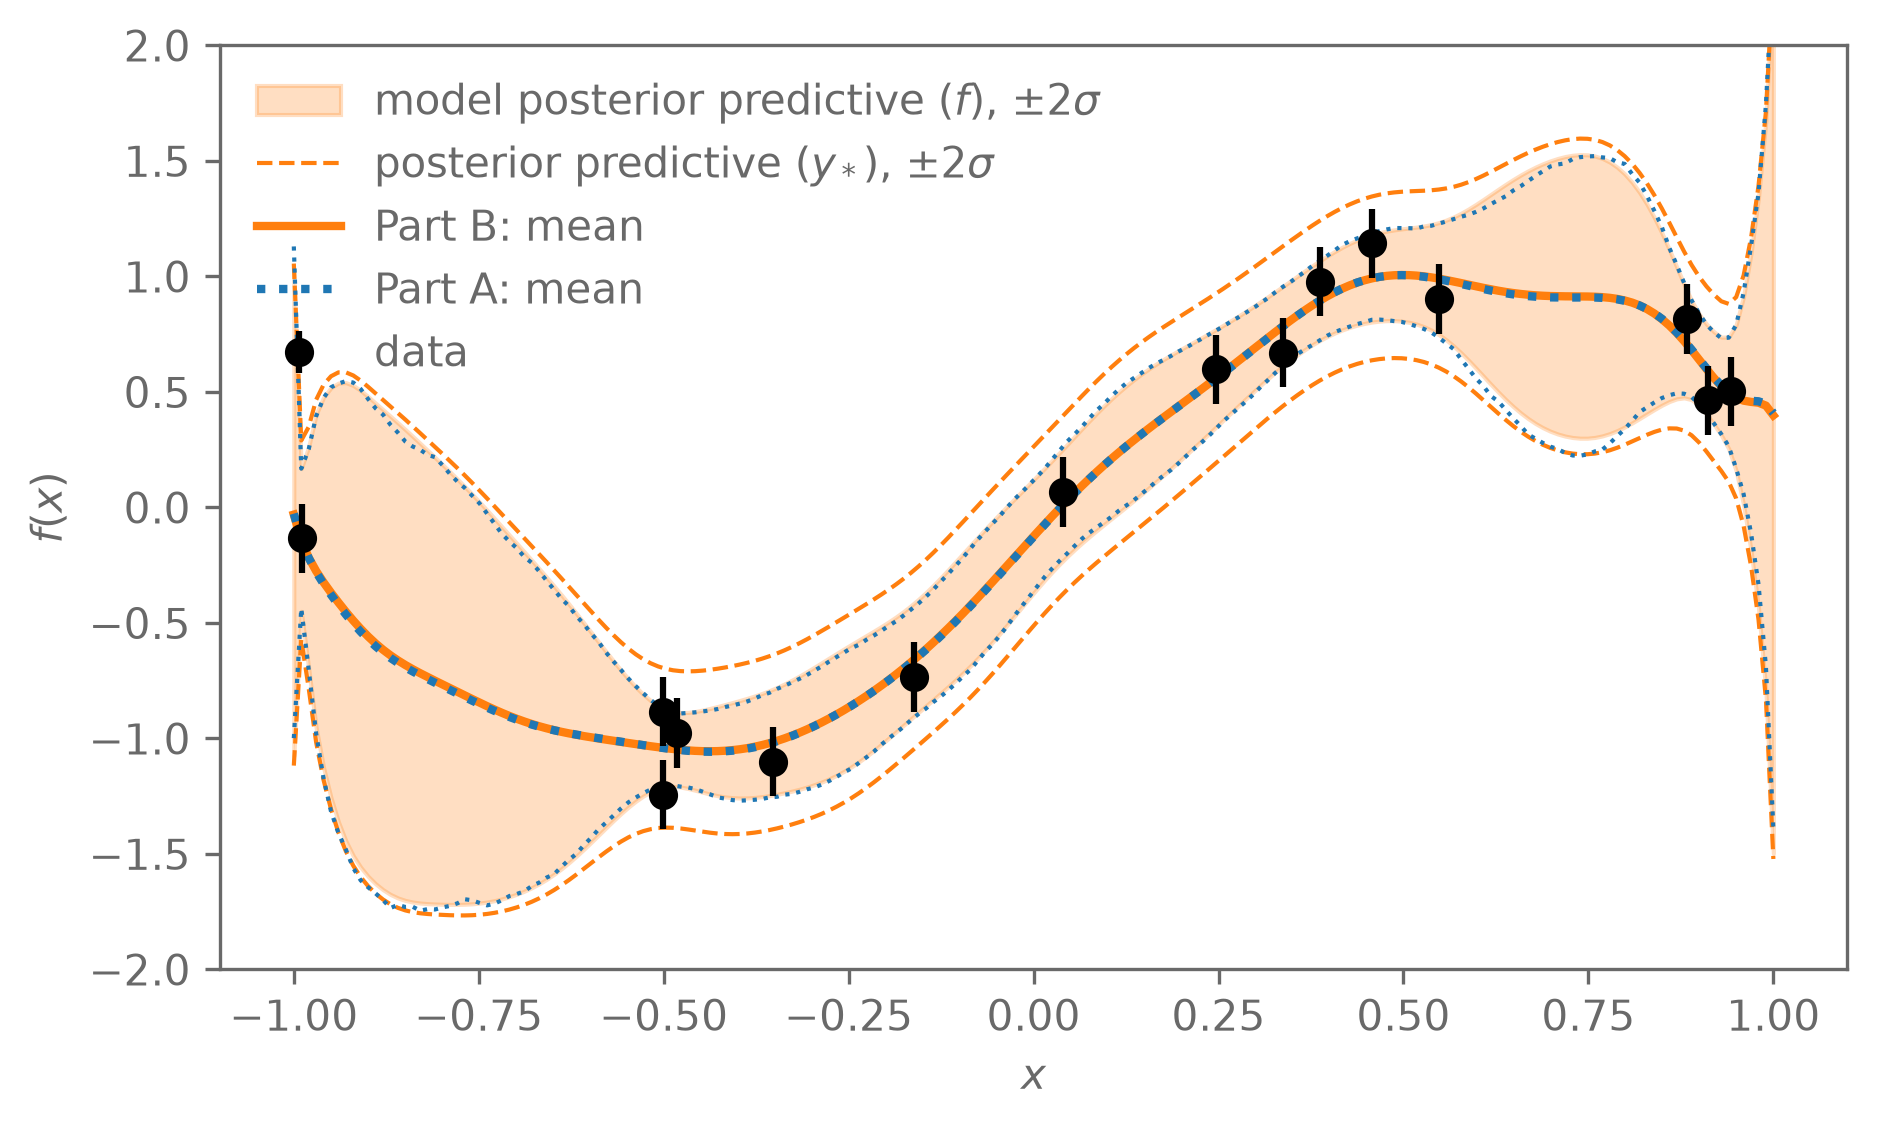

In [11]:
# each hyperparameter sample gives a Gaussian over f(x_test): collect their means and variances
mean_per_sample = np.asarray(samples_marginal["f_test_mean"])     # (n_samples, n_test)
variance_per_sample = np.asarray(samples_marginal["f_test_var"])  # (n_samples, n_test)
# mix those Gaussians: average the means; the variance is the average variance plus the spread of the means
predictive_mean = mean_per_sample.mean(axis=0)
predictive_std = np.sqrt(variance_per_sample.mean(axis=0) + mean_per_sample.var(axis=0))  # law of total variance

posterior_predictive_std = np.sqrt(predictive_std**2 + SIGMA_NOISE**2)                    # adds the noise: new data y_*

# plot both bands, Part A's mean and 95% interval for comparison, and the data
plt.fill_between(x_test, predictive_mean - 2 * predictive_std, predictive_mean + 2 * predictive_std,
                 color="C1", alpha=0.25, label=r"model posterior predictive ($f$), $\pm 2\sigma$")
plt.plot(x_test, predictive_mean - 2 * posterior_predictive_std, "--", color="C1", lw=1,
         label=r"posterior predictive ($y_*$), $\pm 2\sigma$")
plt.plot(x_test, predictive_mean + 2 * posterior_predictive_std, "--", color="C1", lw=1)
plt.plot(x_test, predictive_mean, color="C1", lw=2, label="Part B: mean")
plt.plot(x_test, function_draws.mean(axis=0), ":", color="C0", lw=2, label="Part A: mean")
plt.plot(x_test, np.percentile(function_draws, [2.5, 97.5], axis=0).T, ":", color="C0", lw=1)
plt.errorbar(x_data, y_data, SIGMA_NOISE, fmt="o", color="k", label="data")
plt.ylim(-2, 2); plt.xlabel("$x$"); plt.ylabel("$f(x)$"); plt.legend();

*Solution note.* The Part B mean and band lie on top of Part A's: the same posterior predictive, computed two ways. The posterior predictive for new data is wider by the noise everywhere, which matters most inside the data, where $f$ itself is well determined.

## Part C (extras)

1. **A rougher function.** Fit `chirp_n40.txt` (truth $\sin(6x^2)$, $n = 40$) with `marginal_model`. How does the $\beta$ posterior compare with the sin(3x) data, and why? Check your fit in the explorer (Truth Chirp, $n = 40$).
2. **Unknown noise.** Also sample $\sigma_n \sim \mathcal{HN}(0.5)$ (half-normal) in `marginal_model`. Do you recover $\sigma_n \approx 0.15$ on the sin(3x) data?

chirp, marginal: 

divergences: 0,  ESS(beta): 899
median beta: sin(3x) 2.14  chirp 1.37


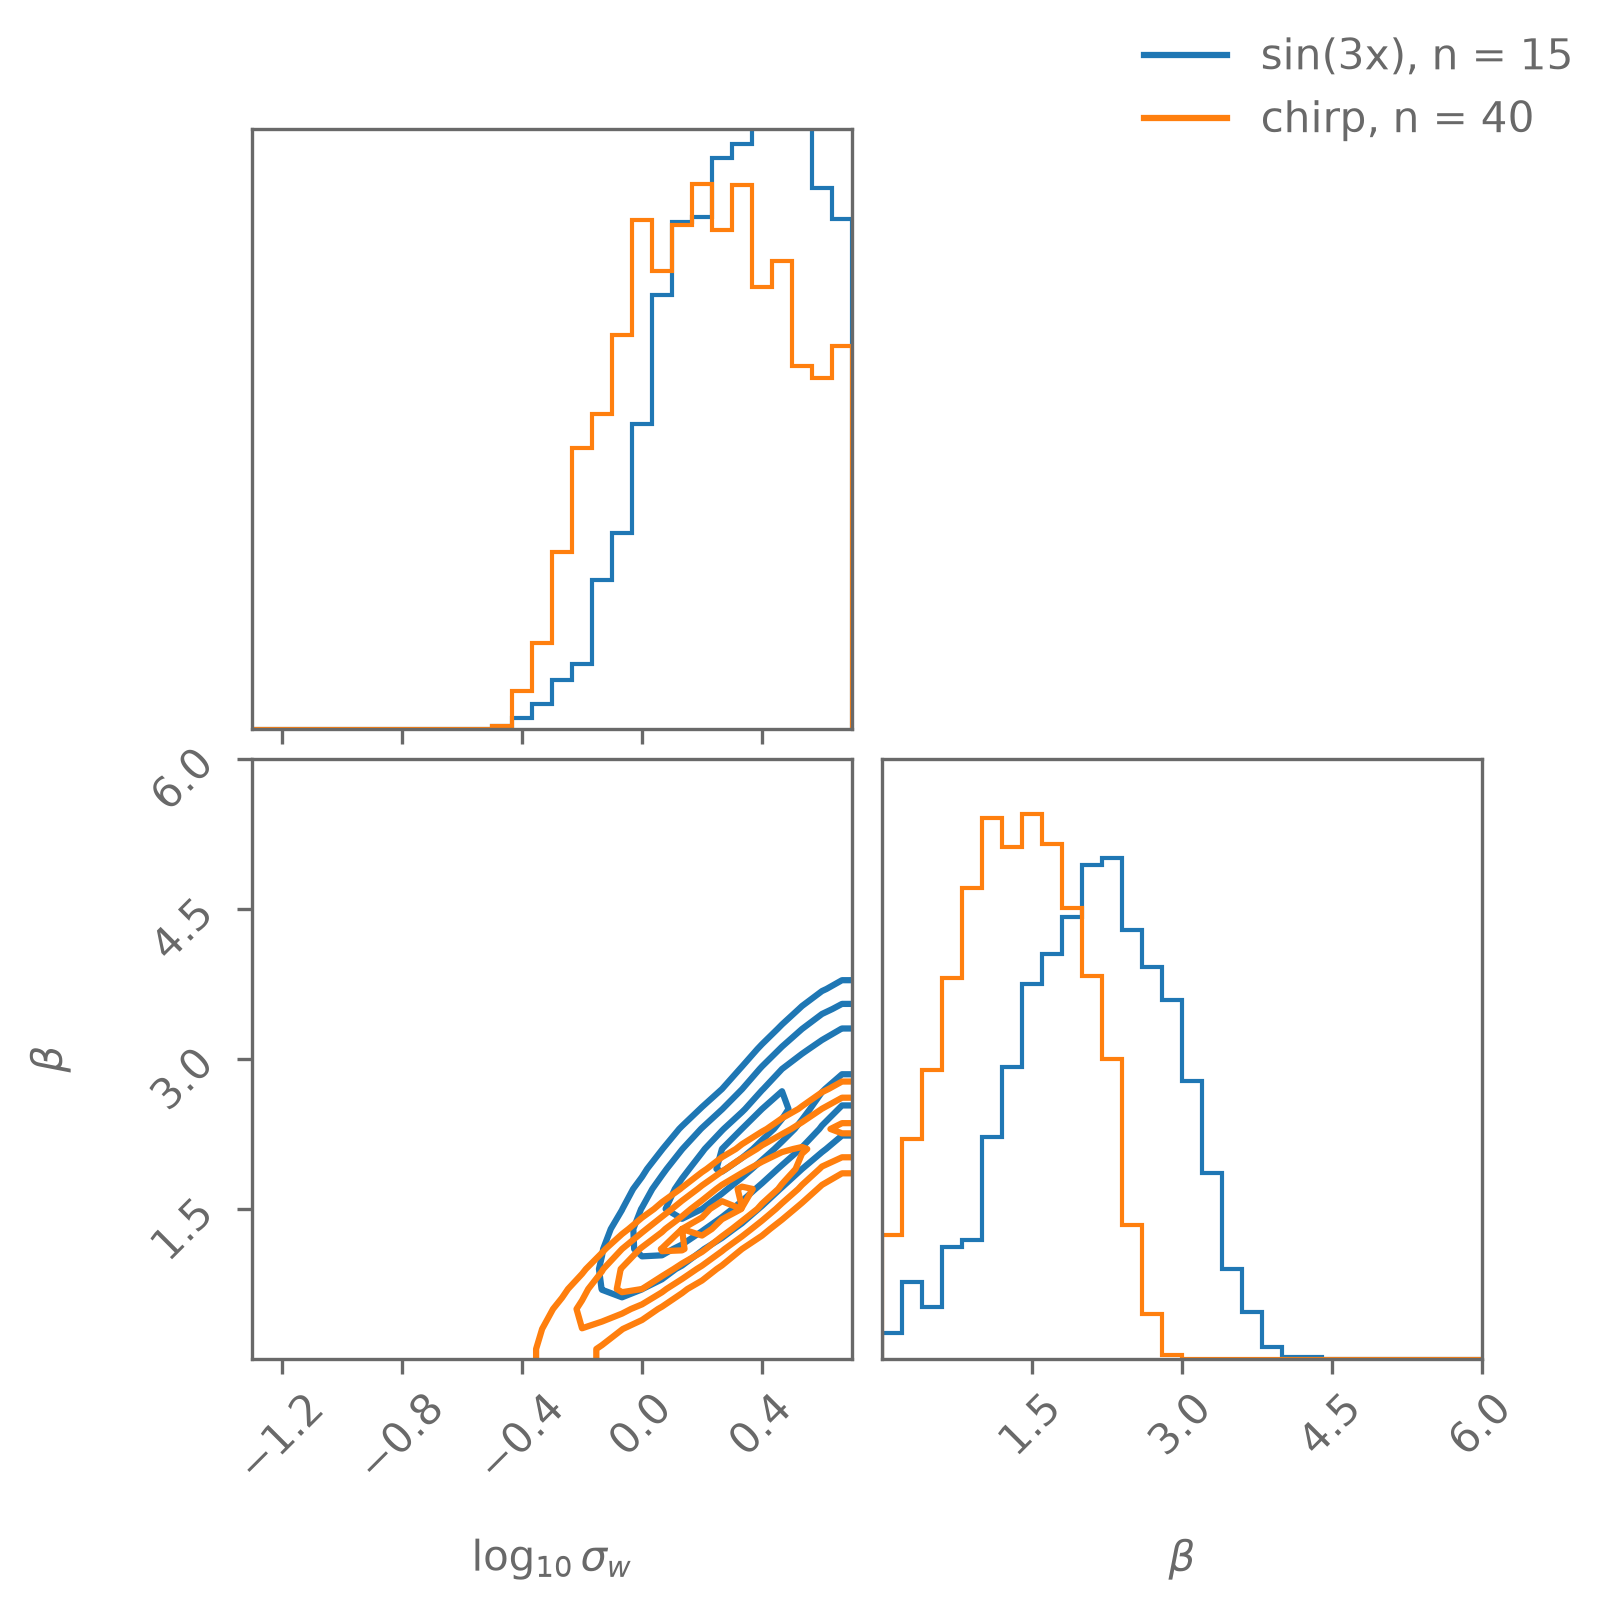

In [12]:
# fit the chirp data with the marginal model and compare its hyperparameters with sin(3x)'s
x_chirp, y_chirp = np.loadtxt(f"{DATA_DIRECTORY}/chirp_n40.txt", unpack=True)
print("chirp, marginal: ", end="")
features_chirp = legendre_features(x_chirp, N_BASIS)   # (n_basis, n_data)
mcmc_chirp = run_nuts(marginal_model, features_chirp, y_chirp, features_test)
plot_hyperparameter_posteriors([samples_marginal, mcmc_chirp.get_samples()], ["sin(3x), n = 15", "chirp, n = 40"]);
# posterior medians of beta for the two data sets
print("median beta: sin(3x)", np.median(samples_marginal["beta"]).round(2),
      " chirp", np.median(mcmc_chirp.get_samples()["beta"]).round(2))

In [13]:
def marginal_model_unknown_noise(features, y_data):
    sigma_w, beta = sample_hyperparameters()
    # the noise level is now a parameter, with a half-normal prior
    sigma_noise = numpyro.sample("sigma_noise", dist.HalfNormal(0.5))
    # same marginal likelihood as Part B, with the sampled noise on the diagonal
    variances = prior_variances(sigma_w, beta, N_BASIS)
    covariance = features.T @ (variances[:, None] * features) + sigma_noise**2 * jnp.eye(features.shape[1])
    numpyro.sample("y", dist.MultivariateNormal(jnp.zeros(features.shape[1]), covariance), obs=y_data)


# sample, then summarize the posterior of the noise level
mcmc_noise = run_nuts(marginal_model_unknown_noise, features, y_data)
noise_samples = np.asarray(mcmc_noise.get_samples()["sigma_noise"])
print("sigma_n: median", np.median(noise_samples).round(3), " 90% interval", np.percentile(noise_samples, [5, 95]).round(3))

divergences: 0,  ESS(beta): 1537
sigma_n: median 0.169  90% interval [0.11  0.283]


*Solution note.* The chirp needs more high-degree terms, so the posterior prefers a smaller $\beta$ (median 1.4, against 2.1 for sin(3x)): a slower decay of the prior widths. With 15 points the noise level is only loosely determined, but it is recovered: median $\sigma_n = 0.17$, 90% interval 0.11–0.28, which covers the true 0.15.

# Exercise 2: the same model with tinygp

[tinygp](https://tinygp.readthedocs.io) builds the covariance matrix $C$ for you from a **kernel** $k(x, x')$, and gives you the marginal likelihood and the predictions. For our model the kernel is the one from the slides,

$$k(x, x') = \phi(x)^\top \Sigma_p\, \phi(x'), \qquad C = K + \sigma_n^2 I, \quad K_{ik} = k(x_i, x_k).$$

## How to use tinygp with numpyro

The snippets below use a **built-in** kernel (`ExpSquared`) on toy data, just to show the interface.

In [14]:
import tinygp
from tinygp import kernels, GaussianProcess
import equinox as eqx

# Toy data, unrelated to Exercise 1
toy_random = np.random.default_rng(1)
x_toy = np.sort(toy_random.uniform(0, 10, 25))                     # (n_data,)
y_toy = np.sin(x_toy) + 0.2 * toy_random.normal(size=x_toy.size)   # (n_data,)
x_toy_test = np.linspace(0, 10, 200)                                # (n_test,)

# 1. A kernel and a GP. `diag` is added to the diagonal of K: the noise variance.
kernel = 1.0**2 * kernels.ExpSquared(scale=1.5)            # amplitude^2 * exp(-(x - x')^2 / (2 scale^2))
gp = GaussianProcess(kernel, x_toy, diag=0.2**2)
print("ln p(y | hyperparameters) =", gp.log_probability(y_toy))   # the evidence, computed for you

ln p(y | hyperparameters) = -6.440529997678526


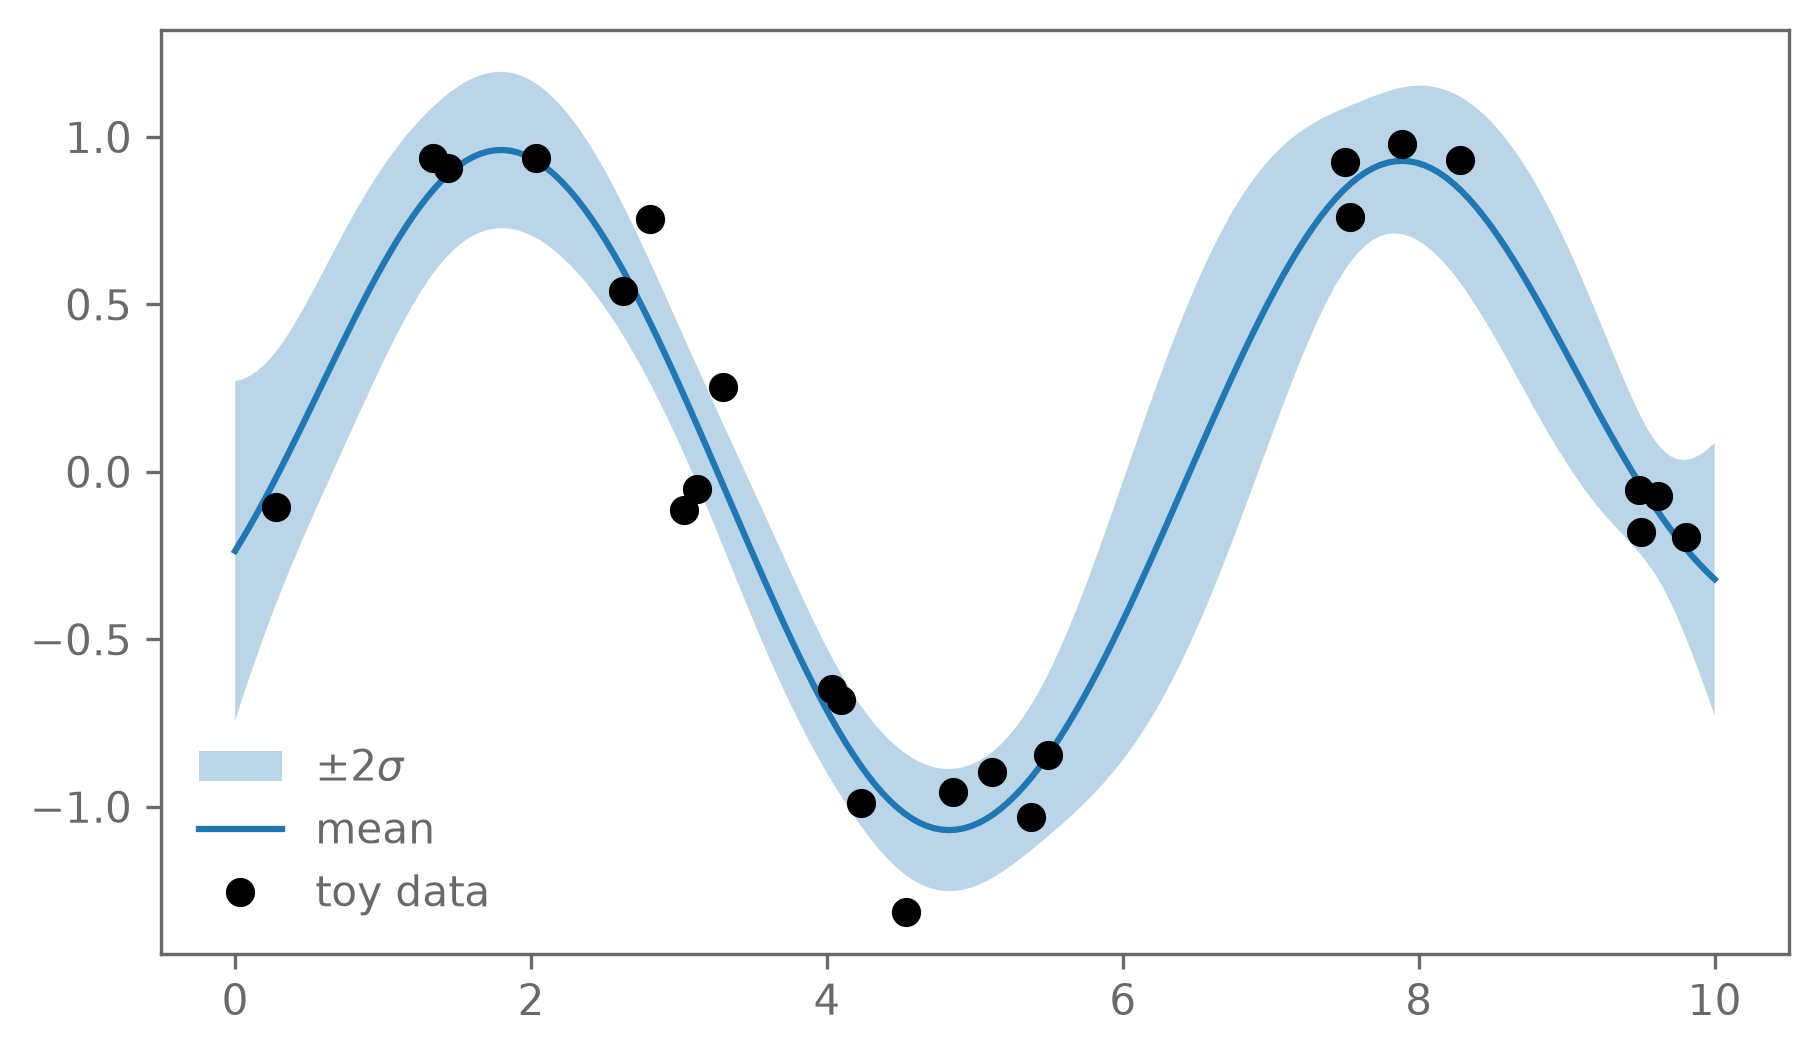

In [15]:
# 2. Inside a numpyro model: priors on the kernel parameters, the GP as the likelihood,
#    and the predictions recorded as deterministic sites.
def toy_model(x_toy, y_toy, x_toy_test):
    # priors on the squared-exponential kernel's amplitude and length scale
    amplitude = numpyro.sample("amplitude", dist.HalfNormal(2.0))
    length_scale = numpyro.sample("length_scale", dist.LogNormal(0.0, 1.0))
    gp = GaussianProcess(amplitude**2 * kernels.ExpSquared(scale=length_scale), x_toy, diag=0.2**2)

    # gp.numpyro_dist() is the multivariate normal N(0, C): the marginal likelihood
    numpyro.sample("y", gp.numpyro_dist(), obs=y_toy)

    # Model predictions (the model posterior predictive for f): condition the GP on the data and
    # evaluate it at the test points. As in Exercise 1 Part B, this is a closed-form Gaussian for each
    # sample of the hyperparameters, so we record its mean and variance rather than sampling it.
    conditioned = gp.condition(y_toy, x_toy_test).gp
    numpyro.deterministic("f_test_mean", conditioned.loc)        # (n_test,)
    numpyro.deterministic("f_test_var", conditioned.variance)    # (n_test,)


# 3. Sample as usual
toy_mcmc = infer.MCMC(infer.NUTS(toy_model), num_warmup=500, num_samples=500, num_chains=4, progress_bar=False)
toy_mcmc.run(jax.random.key(0), x_toy, y_toy, x_toy_test)
toy_samples = toy_mcmc.get_samples()

# combine the per-sample Gaussians as in Exercise 1 Part B, then plot
toy_mean = np.asarray(toy_samples["f_test_mean"]).mean(axis=0)
toy_std = np.sqrt(np.asarray(toy_samples["f_test_var"]).mean(axis=0) + np.asarray(toy_samples["f_test_mean"]).var(axis=0))
# plot the mean, the 2-sigma band and the data
plt.fill_between(x_toy_test, toy_mean - 2 * toy_std, toy_mean + 2 * toy_std, alpha=0.3, label=r"$\pm 2\sigma$")
plt.plot(x_toy_test, toy_mean, label="mean")
plt.plot(x_toy, y_toy, "ko", label="toy data"); plt.legend();

## Your turn

1. **A custom kernel.** Complete `LegendreKernel` below. tinygp calls `evaluate` with *single* inputs (scalars here) and handles the rest.
   - tinygp kernels are [equinox](https://docs.kidger.site/equinox/) modules: the parameters are class attributes, and `n_basis` is marked `eqx.field(static=True)` because it sets array shapes, so it must be a fixed Python integer.
2. **Check it.** On `x_data`, the kernel matrix `LegendreKernel(...)(x_data, x_data)` should equal $\Phi^\top \Sigma_p \Phi$ for the same $(\sigma_w, \beta)$, that is `features.T @ (prior_variances(sigma_w, beta, N_BASIS)[:, None] * features)`. Verify with `np.allclose`.
3. **Sample.** Rewrite `marginal_model` with tinygp (likelihood via `gp.numpyro_dist()`, model predictions via `gp.condition`), run it on the sin(3x) data, and check that you reproduce the $(\sigma_w, \beta)$ posterior and the model posterior predictive of Exercise 1 Part B.
4. **Swap the kernel.** Replace the Legendre kernel with `ExpSquared` (sample its amplitude and length scale) on the same sin(3x) data. Compare the predictions with the Legendre ones, especially near the edges, $x = \pm 1$. This is where the lecture goes next.

In [16]:
class LegendreKernel(tinygp.kernels.Kernel):
    sigma_w: jax.Array | float
    beta: jax.Array | float
    n_basis: int = eqx.field(static=True)   # sets array shapes, so it must be a fixed Python int

    def evaluate(self, first_input, second_input):
        # k(x, x') = phi(x)^T Sigma_p phi(x'): sum the products of the basis functions,
        # each weighted by its prior variance
        variances = prior_variances(self.sigma_w, self.beta, self.n_basis)      # (n_basis,)
        return jnp.sum(legendre_features(first_input, self.n_basis) * variances
                       * legendre_features(second_input, self.n_basis))

In [17]:
# check the kernel against the feature-space formula at one setting of (sigma_w, beta)
sigma_w_check, beta_check = 1.3, 2.0
kernel_matrix = LegendreKernel(sigma_w_check, beta_check, N_BASIS)(x_data, x_data)        # (n_data, n_data)
by_hand = features.T @ (prior_variances(sigma_w_check, beta_check, N_BASIS)[:, None] * features)
print("kernel matrix matches Phi^T Sigma_p Phi:", np.allclose(kernel_matrix, by_hand))

kernel matrix matches Phi^T Sigma_p Phi: True


divergences: 0,  ESS(beta): 764


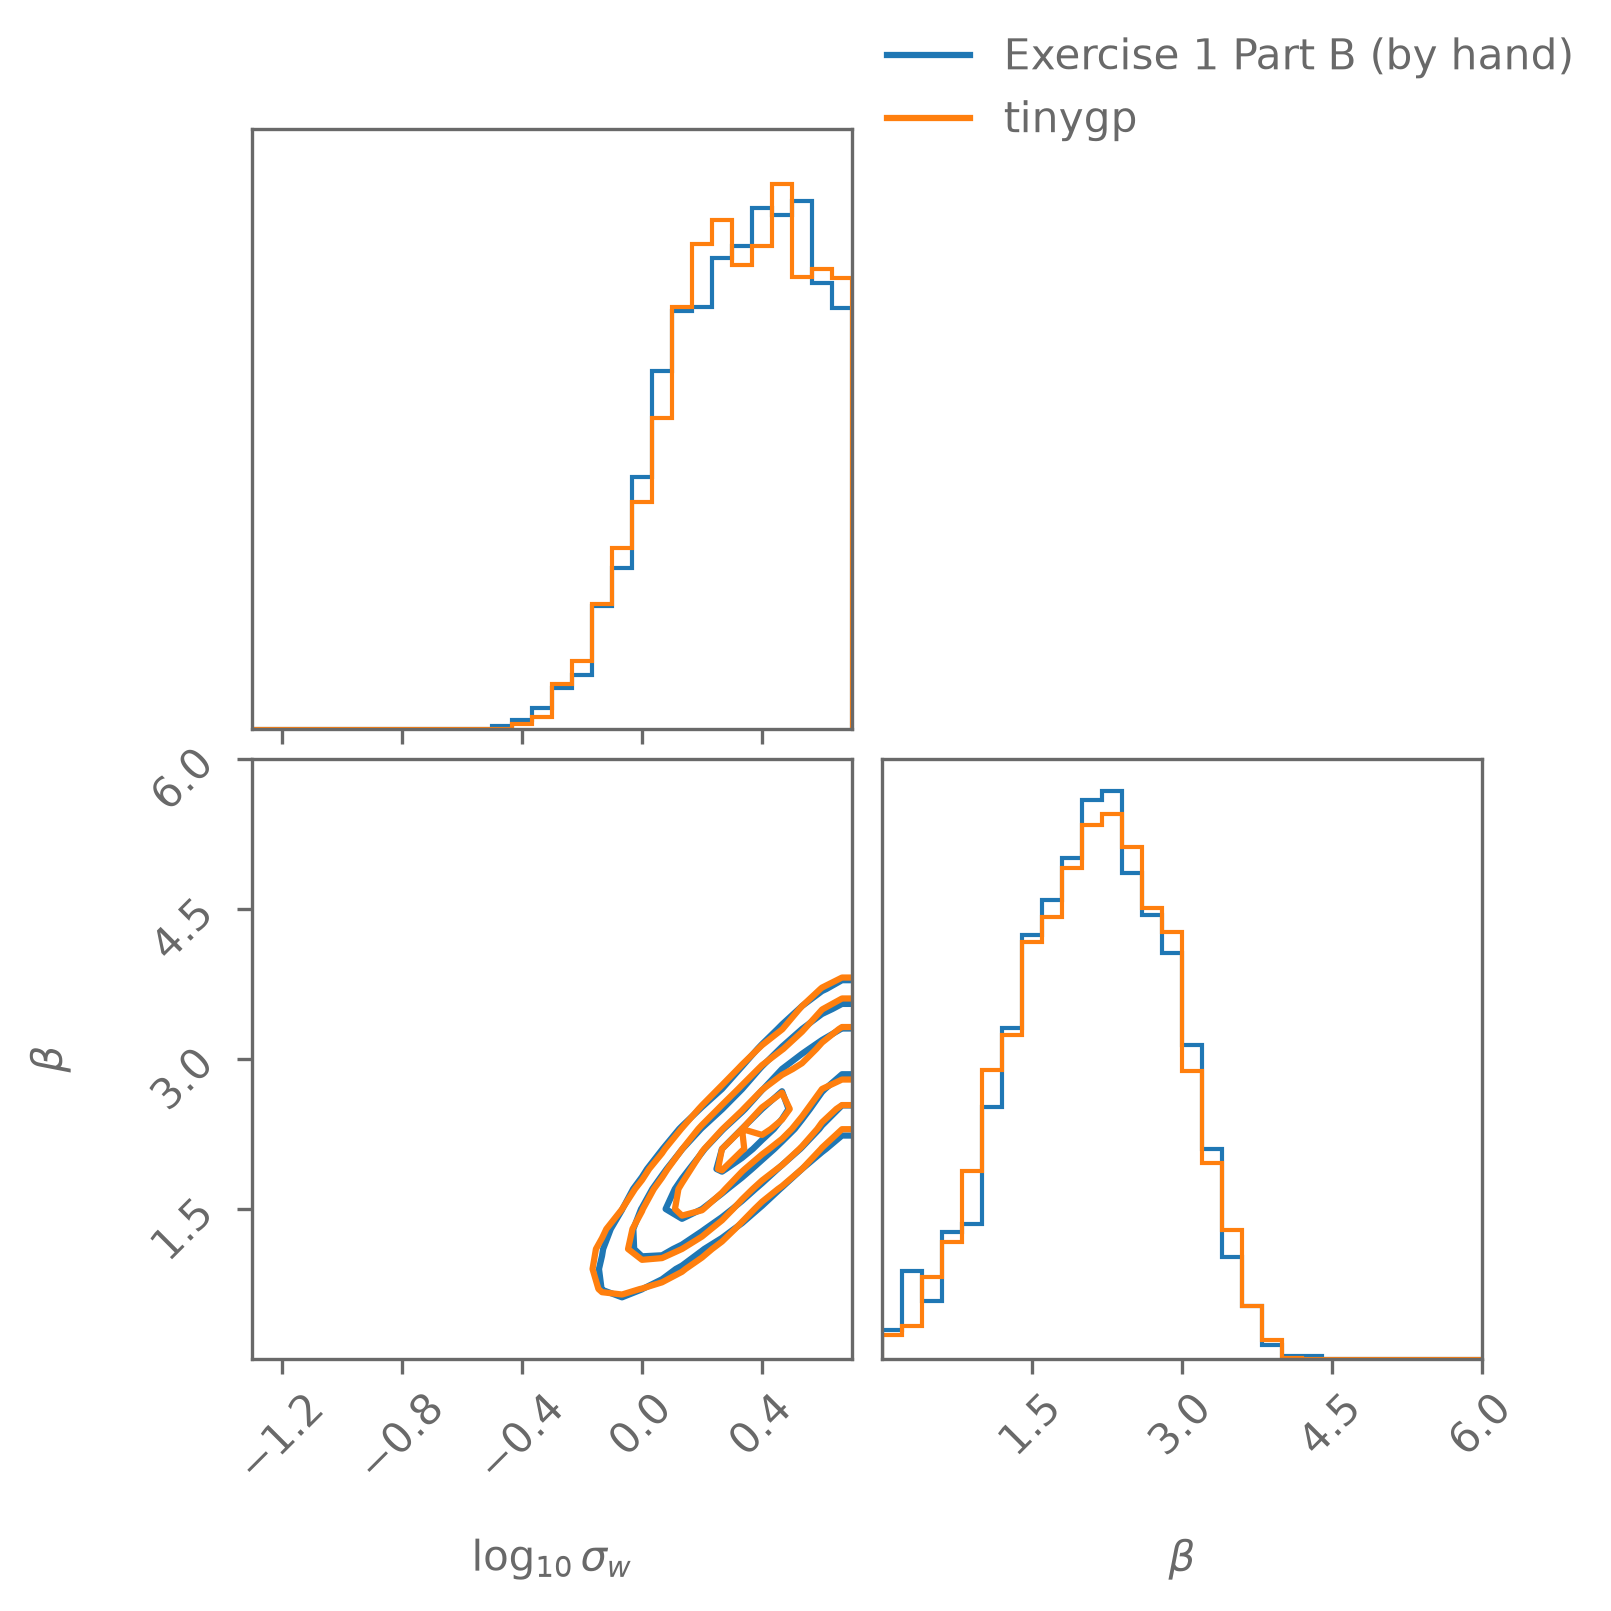

largest difference in posterior-mean prediction: 0.001


In [18]:
def tinygp_legendre_model(x_data, y_data, x_test):
    sigma_w, beta = sample_hyperparameters()
    # a GP with the Legendre kernel and the noise on the diagonal: the same model as Part B
    gp = GaussianProcess(LegendreKernel(sigma_w, beta, N_BASIS), x_data, diag=SIGMA_NOISE**2)
    numpyro.sample("y", gp.numpyro_dist(), obs=y_data)
    # predictions at the test points, recorded rather than sampled
    conditioned = gp.condition(y_data, x_test).gp
    numpyro.deterministic("f_test_mean", conditioned.loc)
    numpyro.deterministic("f_test_var", conditioned.variance)


# sample, and compare with Part B done by hand
mcmc_tinygp = run_nuts(tinygp_legendre_model, x_data, y_data, x_test)
samples_tinygp = mcmc_tinygp.get_samples()
plot_hyperparameter_posteriors([samples_marginal, samples_tinygp], ["Exercise 1 Part B (by hand)", "tinygp"]);
plt.show()
# the posterior-mean predictions should agree, up to Monte Carlo noise
print("largest difference in posterior-mean prediction:",
      np.abs(np.asarray(samples_tinygp["f_test_mean"]).mean(0) - np.asarray(samples_marginal["f_test_mean"]).mean(0)).max().round(3))

Legendre kernel, M = 20: 2-sigma at x = -1, 0, +1: 1.04, 0.24, 1.89
ExpSquared kernel: 2-sigma at x = -1, 0, +1: 0.30, 0.20, 0.28


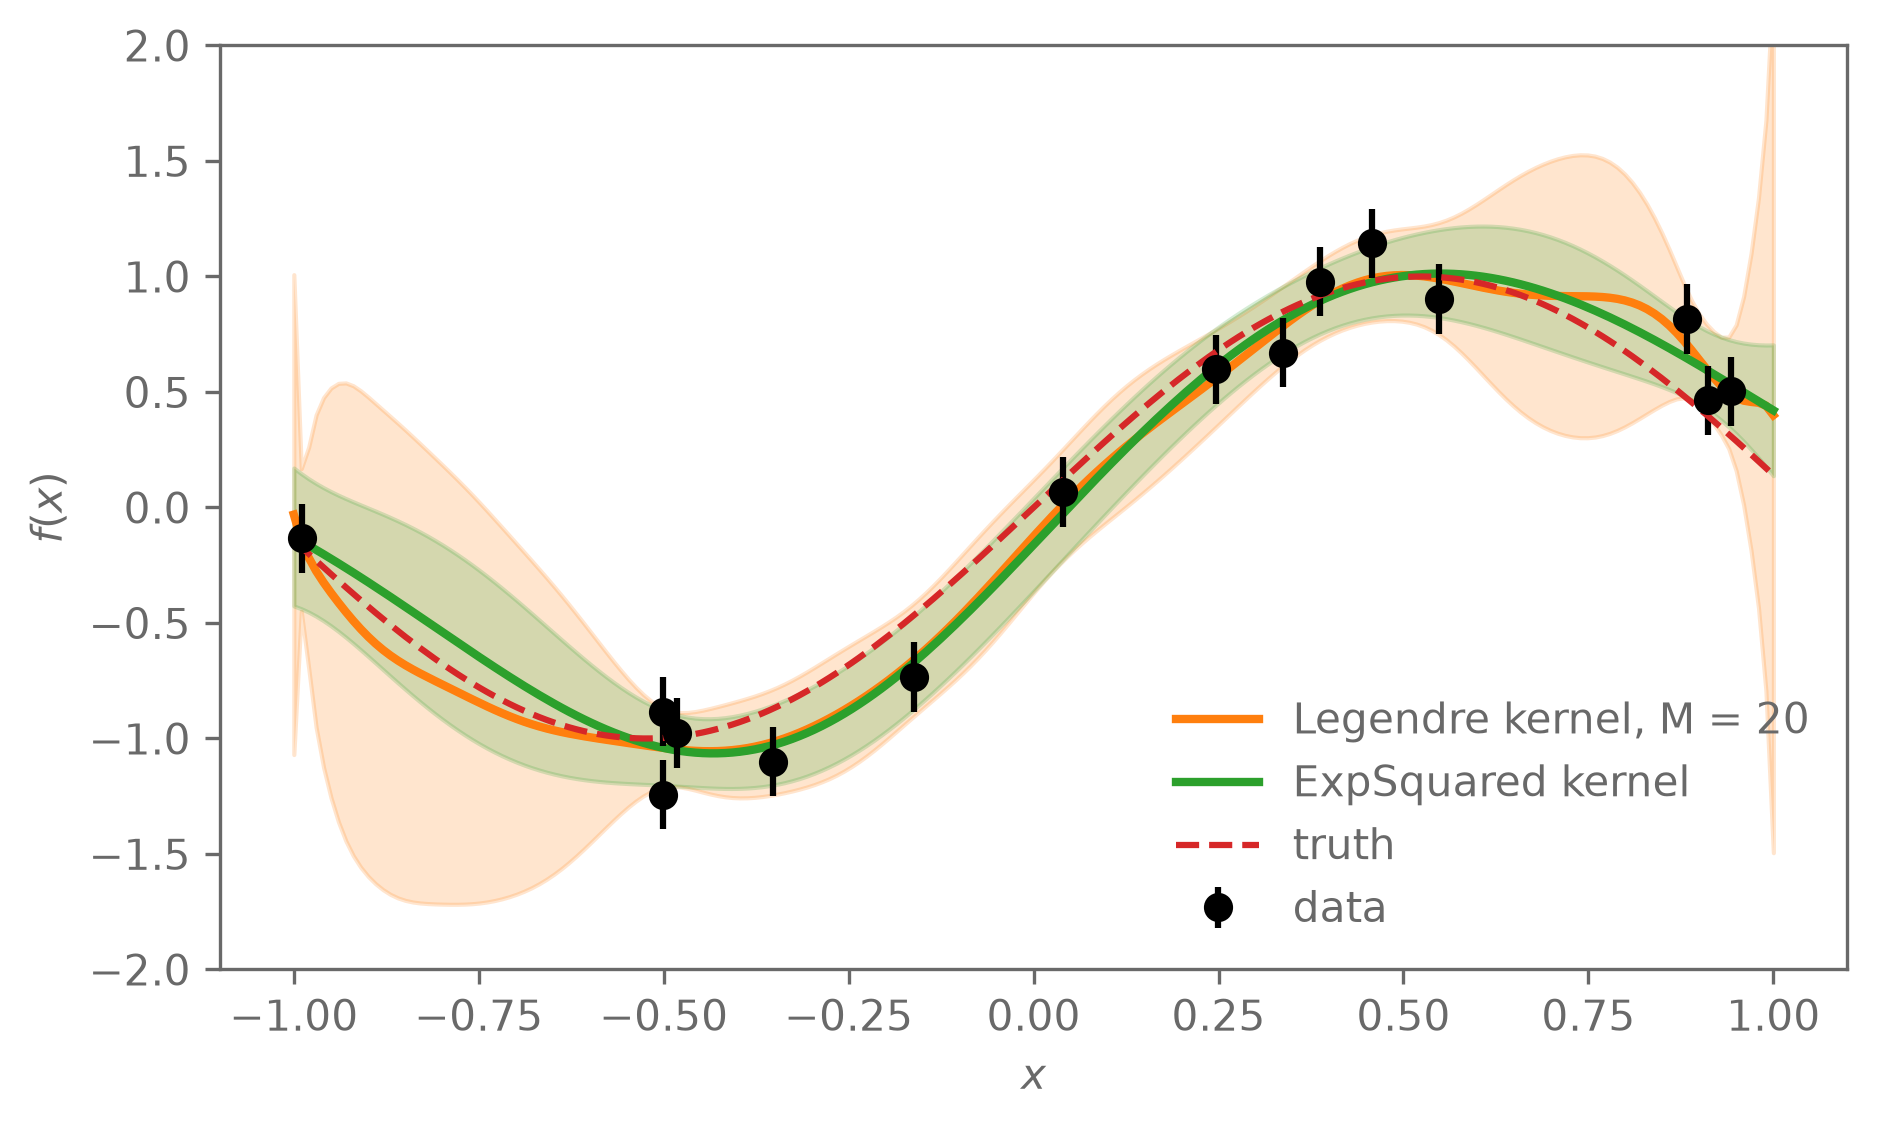

In [19]:
def tinygp_expsquared_model(x_data, y_data, x_test):
    # priors on the squared-exponential kernel's amplitude and length scale
    amplitude = numpyro.sample("amplitude", dist.HalfNormal(2.0))
    length_scale = numpyro.sample("length_scale", dist.LogNormal(np.log(0.3), 1.0))
    gp = GaussianProcess(amplitude**2 * kernels.ExpSquared(scale=length_scale), x_data, diag=SIGMA_NOISE**2)
    numpyro.sample("y", gp.numpyro_dist(), obs=y_data)
    conditioned = gp.condition(y_data, x_test).gp
    numpyro.deterministic("f_test_mean", conditioned.loc)
    numpyro.deterministic("f_test_var", conditioned.variance)


# sample, then plot both models' predictions with their 2-sigma bands
mcmc_expsquared = infer.MCMC(infer.NUTS(tinygp_expsquared_model), num_warmup=1000, num_samples=1000,
                             num_chains=4, progress_bar=False)
mcmc_expsquared.run(jax.random.key(0), x_data, y_data, x_test)

for samples, label, color in [(samples_tinygp, "Legendre kernel, M = 20", "C1"),
                               (mcmc_expsquared.get_samples(), "ExpSquared kernel", "C2")]:
    mean_per_sample = np.asarray(samples["f_test_mean"]); variance_per_sample = np.asarray(samples["f_test_var"])
    mean = mean_per_sample.mean(0); std = np.sqrt(variance_per_sample.mean(0) + mean_per_sample.var(0))
    plt.fill_between(x_test, mean - 2 * std, mean + 2 * std, color=color, alpha=0.2)
    plt.plot(x_test, mean, color=color, lw=2, label=label)
    # width of the band at the edges and in the middle
    print(f"{label}: 2-sigma at x = -1, 0, +1: {2 * std[0]:.2f}, {2 * std[len(x_test) // 2]:.2f}, {2 * std[-1]:.2f}")
plt.errorbar(x_data, y_data, SIGMA_NOISE, fmt="o", color="k", label="data")
plt.plot(x_test, np.sin(3 * x_test), "--", color="C3", label="truth")
plt.ylim(-2, 2); plt.xlabel("$x$"); plt.ylabel("$f(x)$"); plt.legend();

*Solution note.* Inside the data the two kernels agree. At the edges they don't: the Legendre band is $2\sigma \approx 1.0$ at $x = -1$ and $1.9$ at $x = +1$, against $0.24$ at $x = 0$, while the ExpSquared band stays at 0.2–0.3 everywhere. Every Legendre polynomial reaches its largest size at the edges, $|P_j(\pm 1)| = 1$, so the Legendre prior puts most of its variance there, and the high-degree weights the data don't pin down make the band flare, even next to data points. The ExpSquared kernel is stationary: its prior variance is the same everywhere, and its band only grows where the data run out.

# Exercise 3: building a kernel for Mauna Loa CO$_2$

In the lecture we fit the CO$_2$ record with two components, a squared-exponential trend and a quasi-periodic seasonal term, and found two problems:

* the **residuals are correlated**: there are multi-year bumps (around 1973 and 1998, for example) that neither component explains;
* the **forecast flattens**: a squared-exponential trend reverts to the mean when extrapolated.

Your job is to build a better kernel. As in the lecture, we hold out the last decade (from 2016.75) and fit the hyperparameters by maximizing the evidence on the rest.

**How to compare models.** Two scores, and they will not always agree:

1. the log evidence on the training data (what we maximized);
2. the **log predictive density of the held-out decade** under the posterior predictive (Week 7): $\sum_{\rm held\ out} \ln \mathcal N_y\big(y_i;\ m(t_i),\ v(t_i) + \sigma_n^2\big)$.

Careful: we *optimized* the evidence over the hyperparameters, so the difference between the maximized evidences of kernels with different numbers of hyperparameters is not a fair Bayes factor. The held-out score avoids this, as long as you don't tune many models against it.

**Tasks**

1. Run the lecture model below and note both scores.
2. **Medium-term irregularities.** Add a third component for the correlated residuals, using a kernel we did *not* use in the lecture: try `kernels.RationalQuadratic` and `kernels.Matern32` (or `Matern52`). What length scales come out? Compare both scores.
3. **The trend.** Add a linear component (`kernels.DotProduct`) to the trend so that the forecast no longer has to revert to the mean. Does it help?
4. **The seasonal term.** Replace the quasi-periodic term by a strictly periodic one (`ExpSineSquared` alone). Which score prefers which model?
5. Put your results in a table. Where do the evidence and the held-out score disagree, and why might that be?
6. Plot the forecast of your best model over the held-out decade, and its components. To get one component, condition on the data but predict with that term of the kernel only, and without the mean: `gp.condition(co2_train, times, kernel=component, include_mean=False).gp`.

In [20]:
import pandas as pd
import scipy.optimize
from scipy.stats import norm

# Notation
#   n_train    number of training months (before 2016.75)
#   n_holdout  number of held-out months
co2_table = pd.read_csv("../lectures/data/co2/co2_mm_mlo.csv", comment="#")
time_years = co2_table["decimal date"].to_numpy() - 1958.0          # years since 1958
co2 = co2_table["average"].to_numpy()                               # ppm
# train on the data before late 2016, and hold out the rest to test the forecasts
is_train = time_years < 2016.75 - 1958.0
time_train, co2_train = time_years[is_train], co2[is_train]         # (n_train,)
time_holdout, co2_holdout = time_years[~is_train], co2[~is_train]   # (n_holdout,)


def fit_kernel(make_kernel, initial_params):
    """Maximize the evidence over the hyperparameters; return (best params, ln evidence, fitted GP).

    make_kernel(params) must return a tinygp kernel. Every params entry is unconstrained: store
    positive quantities as logs. A constant mean ("mean") and the noise ("log_noise") are added here.
    """

    # append a constant mean and the (log) noise to the initial parameters
    initial = {"mean": co2_train.mean(), "log_noise": np.log(0.5), **initial_params}

    # get the list of names of the parameters
    names = list(initial)

    # build the Gaussian process from whatever "make kernel" function we give it,
    # from a flat vector of parameter values (the form scipy's optimizer works with)
    def build_gp_object(vector):
        # build the dictionary we need from the names of the parameters and
        # the raw vector
        params = dict(zip(names, vector))
        # build the GP object, including noise.
        return GaussianProcess(make_kernel(params), time_train, diag=jnp.exp(2 * params["log_noise"]), mean=params["mean"])

    # evaluate the negative log likelihood and its gradient for the gp object we build
    value_and_gradient = jax.jit(jax.value_and_grad(lambda vector: -build_gp_object(vector).log_probability(co2_train)))

    # optimize
    result = scipy.optimize.minimize(lambda vector: [np.asarray(value) for value in value_and_gradient(jnp.asarray(vector))],
                                     np.array([initial[name] for name in names]), jac=True, method="L-BFGS-B")
    # best-fit hyperparameters
    best = jnp.asarray(result.x)
    return dict(zip(names, best)), -result.fun, build_gp_object(best)


def held_out_score(gp, params):
    """Log predictive density of the held-out decade (posterior predictive: includes the noise)."""
    # predict the held-out months from the training data; the spread includes the noise
    prediction = gp.condition(co2_train, time_holdout).gp
    predictive_std = np.sqrt(prediction.variance + np.exp(2 * float(params["log_noise"])))
    # sum of the log densities of the held-out data under that prediction
    return float(norm.logpdf(co2_holdout, prediction.loc, predictive_std).sum())

In [21]:
# The lecture model: squared-exponential trend + quasi-periodic seasonal term
def lecture_kernel(params):
    # long-term trend: a smooth squared exponential with a long length scale
    trend = jnp.exp(2 * params["log_amp_trend"]) * kernels.ExpSquared(scale=jnp.exp(params["log_scale_trend"]))
    # seasonal term: periodic, times a squared exponential so its shape can drift slowly
    seasonal = (jnp.exp(2 * params["log_amp_season"])
                * kernels.ExpSquared(scale=jnp.exp(params["log_scale_decay"]))
                * kernels.ExpSineSquared(scale=jnp.exp(params["log_period"]), gamma=jnp.exp(params["log_gamma"])))
    return trend + seasonal


# starting values (logs of the amplitudes and length scales), then fit
lecture_initial = {"log_amp_trend": np.log(50.0), "log_scale_trend": np.log(50.0), "log_amp_season": np.log(2.0),
                   "log_scale_decay": np.log(50.0), "log_period": 0.0, "log_gamma": 0.0}
lecture_params, lecture_evidence, lecture_gp = fit_kernel(lecture_kernel, lecture_initial)
print(f"lecture model: ln evidence {lecture_evidence:.1f}, held-out log predictive density {held_out_score(lecture_gp, lecture_params):.1f}")

lecture model: ln evidence -507.2, held-out log predictive density -247.7


In [22]:
def add_extra_kernel(base_kernel, extra_kernel_type):
    """Return a kernel function: base kernel + an extra kernel (rational quadratic or Matern 3/2)."""

    # we need a "make_kernel(params)" function
    # so we make that function here, such that it
    # adds some base kernel (e.g. the lecture kernel above) to
    # some new kernel (e.g. rational quadratic)
    def make_kernel(params):
        amplitude = jnp.exp(2 * params["log_amplitude_extra"])
        length_scale = jnp.exp(params["log_length_scale_extra"])
        if extra_kernel_type == "rational_quadratic":
            component = kernels.RationalQuadratic(scale=length_scale, alpha=jnp.exp(params["log_shape_extra"]))
        else:
            component = kernels.Matern32(scale=length_scale)
        return base_kernel(params) + amplitude * component
    return make_kernel


def strictly_periodic_kernel(params):
    # like the lecture kernel, but the seasonal shape never changes (no decay term)
    trend = jnp.exp(2 * params["log_amp_trend"]) * kernels.ExpSquared(scale=jnp.exp(params["log_scale_trend"]))
    seasonal = jnp.exp(2 * params["log_amp_season"]) * kernels.ExpSineSquared(scale=jnp.exp(params["log_period"]), gamma=jnp.exp(params["log_gamma"]))
    return trend + seasonal


def linear_plus_lecture_kernel(params):
    # a straight-line (dot product) kernel added to the lecture kernel
    return jnp.exp(2 * params["log_amp_linear"]) * kernels.DotProduct() + lecture_kernel(params)


# starting values for the extra kernel's parameters, and the models to compare
extra_initial = {"log_amplitude_extra": np.log(0.5), "log_length_scale_extra": 0.0, "log_shape_extra": 0.0}
candidates = {
    "lecture: SE trend + quasi-periodic": (lecture_kernel, lecture_initial),
    "lecture + RationalQuadratic": (add_extra_kernel(lecture_kernel, "rational_quadratic"), {**lecture_initial, **extra_initial}),
    "lecture + Matern32": (add_extra_kernel(lecture_kernel, "matern"), {**lecture_initial, **extra_initial}),
    "strictly periodic season + RQ": (add_extra_kernel(strictly_periodic_kernel, "rational_quadratic"), {**lecture_initial, **extra_initial}),
    "linear + SE trend, quasi-periodic, RQ": (add_extra_kernel(linear_plus_lecture_kernel, "rational_quadratic"),
                                              {**lecture_initial, **extra_initial, "log_amp_linear": np.log(0.05)}),
}
# fit each model; print its evidence and how well it predicts the held-out decade
fits = {}
print(f"{'model':40s} {'ln evidence':>12s} {'held-out lpd':>13s}")
for label, (make_kernel, initial) in candidates.items():
    params, evidence, gp = fit_kernel(make_kernel, initial)
    fits[label] = (params, gp, make_kernel)
    print(f"{label:40s} {evidence:12.1f} {held_out_score(gp, params):13.1f}")

# the fitted length scale of the extra component, in years
for label, (params, gp, make_kernel) in fits.items():
    if "log_length_scale_extra" in params:
        print(f"{label:40s} extra length scale {np.exp(float(params['log_length_scale_extra'])):.2f} yr")

model                                     ln evidence  held-out lpd


lecture: SE trend + quasi-periodic             -507.2        -247.7


lecture + RationalQuadratic                    -178.3        -153.7


lecture + Matern32                             -189.5        -258.4


strictly periodic season + RQ                  -197.8        -182.6


linear + SE trend, quasi-periodic, RQ          -177.9        -149.9
lecture + RationalQuadratic              extra length scale 0.80 yr
lecture + Matern32                       extra length scale 0.68 yr
strictly periodic season + RQ            extra length scale 0.89 yr
linear + SE trend, quasi-periodic, RQ    extra length scale 1.23 yr


*Solution note.*
- **Extra component.** Adding one helps a lot on both scores (evidence $-507 \to -178$, held-out $-248 \to -154$). Its fitted length scale is short, 0.7–1.2 yr: it picks up wiggles on scales of months to a year rather than the multi-year bumps we built it for.
- **Matérn-3/2** has a much higher evidence than the lecture model but the *worst* held-out score: it is rough enough to soak up the training wiggles, and its forecast wanders (see the bad forecast below).
- **Strictly periodic season.** It loses on both scores here. Its scores also depend on which optimum the optimizer lands in (try a few starting points): with ~11 hyperparameters the evidence has several local maxima, and type-II maximum likelihood just picks one.
- **Linear trend.** It barely moves the evidence ($+0.4$) and improves the held-out score a little ($+3.8$), too little to call: try other starting values and see how much the scores move. The component plot below shows why: the fitted linear term is tiny, and the long squared-exponential trend does the work.
- **Why the two scores disagree.** The evidence is a product of one-step-ahead predictions, $p(y_1)\,p(y_2 \mid y_1)\,p(y_3 \mid y_1, y_2) \cdots$, each made from the months just before, so it rewards a model that tracks short wiggles. The held-out score asks for a 10-year extrapolation, which depends on how the trend continues. On top of that, optimized evidences are not proper Bayes factors: the hyperparameters were tuned on the same data, and the models have different numbers of them.

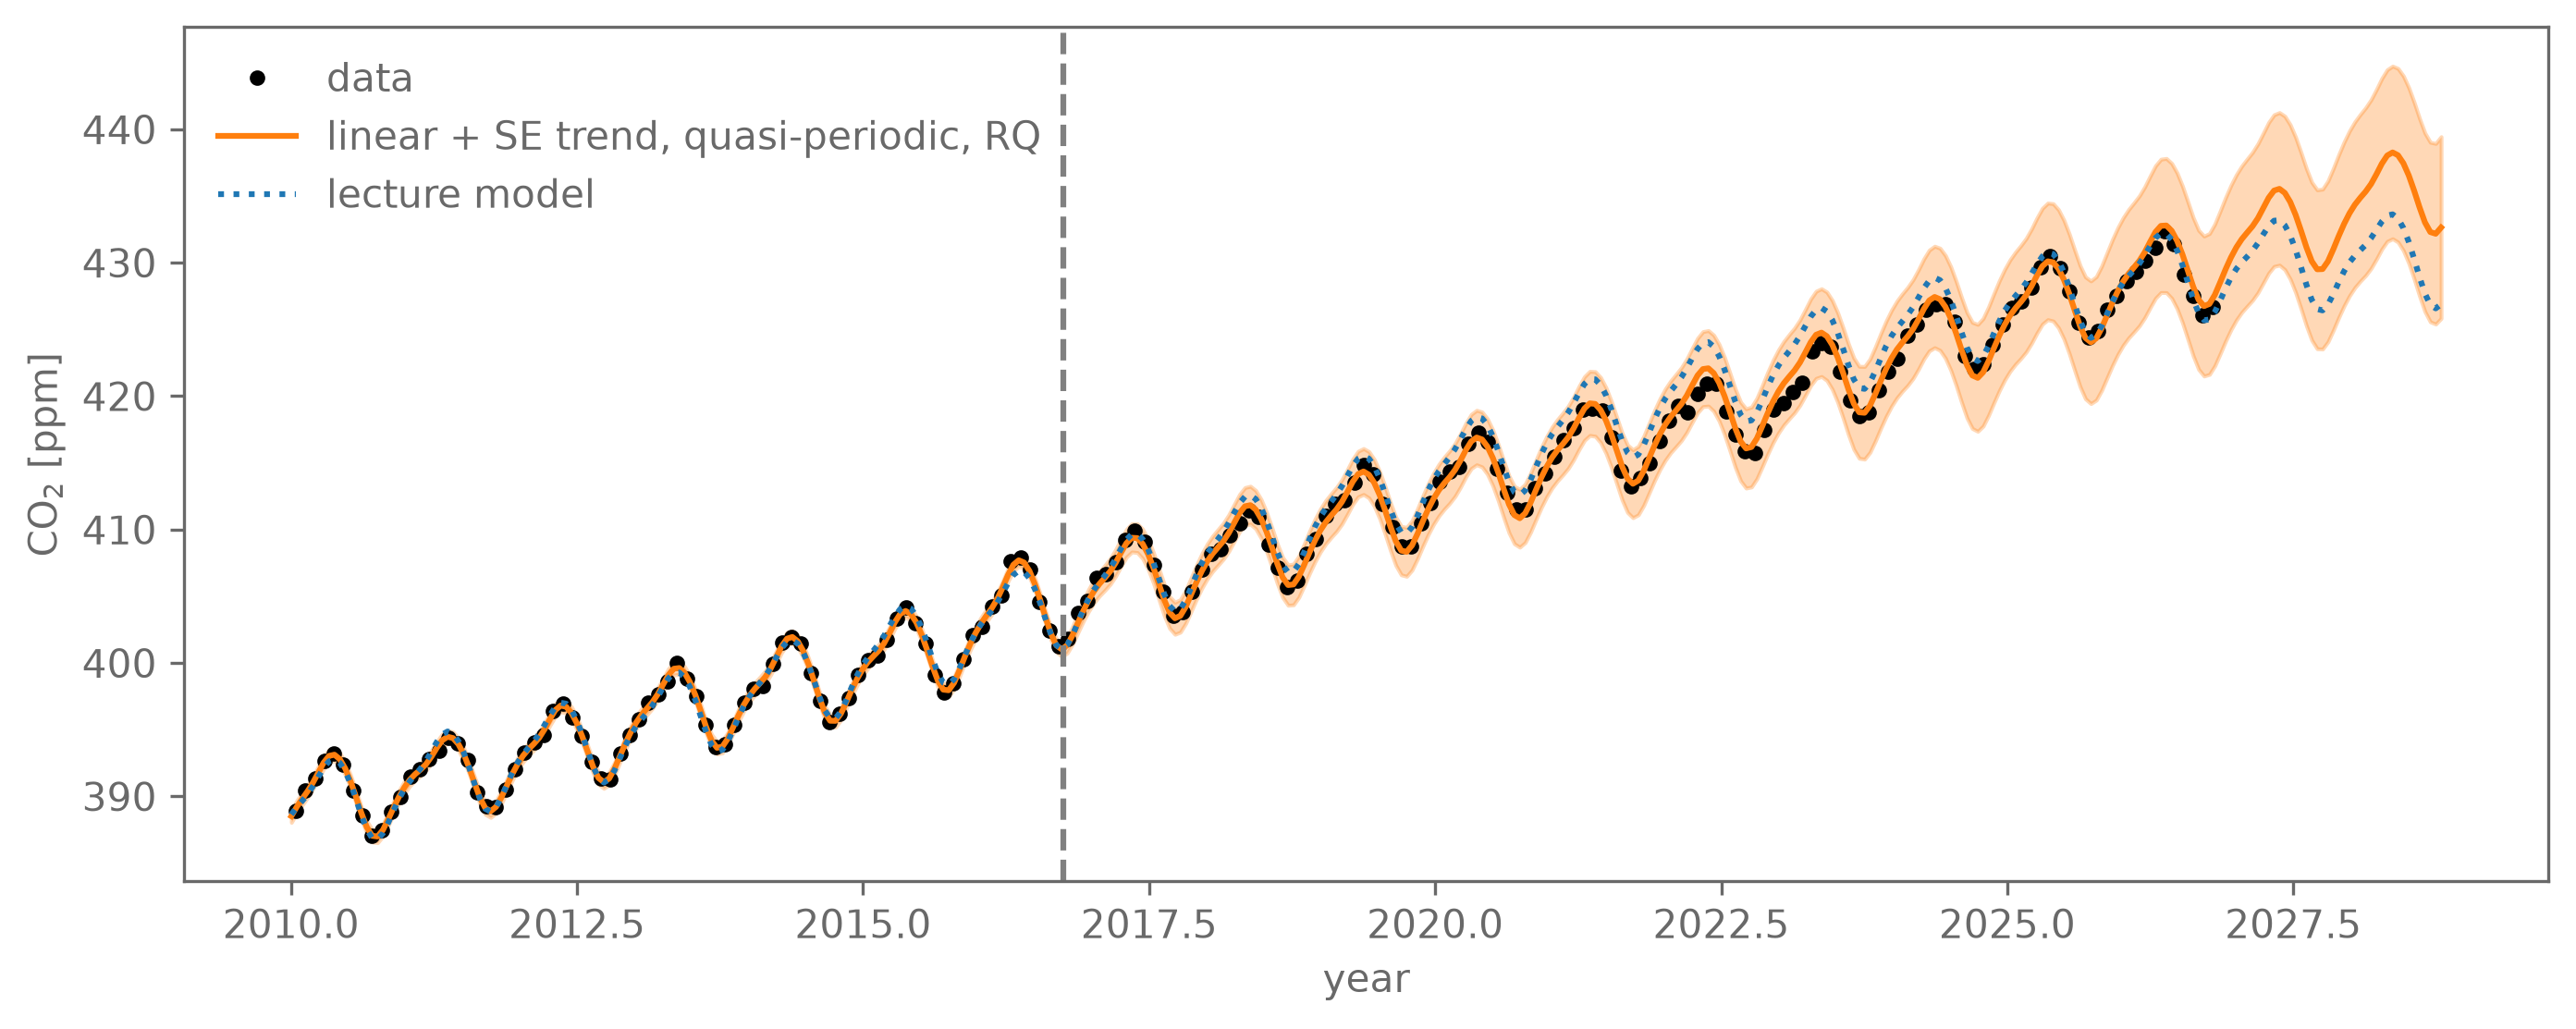

In [23]:
# forecast with the best model, from the training data to two years past the last data point
best_label = "linear + SE trend, quasi-periodic, RQ"
best_params, best_gp, _ = fits[best_label]
time_forecast = np.linspace(time_years.min(), time_years.max() + 2, 1500)
forecast = best_gp.condition(co2_train, time_forecast).gp
forecast_std = np.sqrt(forecast.variance + np.exp(2 * float(best_params["log_noise"])))
lecture_forecast = lecture_gp.condition(co2_train, time_forecast).gp

# plot from 2010 on: the data, the best model's forecast with a 2-sigma band, and the lecture model's
in_view = time_forecast + 1958 > 2010
figure, axis = plt.subplots(figsize=(11, 4))
axis.plot(time_years[time_years + 1958 > 2010] + 1958, co2[time_years + 1958 > 2010], ".", color="k", label="data")
axis.plot(time_forecast[in_view] + 1958, forecast.loc[in_view], color="C1", label=best_label)
axis.fill_between(time_forecast[in_view] + 1958, (forecast.loc - 2 * forecast_std)[in_view],
                  (forecast.loc + 2 * forecast_std)[in_view], color="C1", alpha=0.3)
axis.plot(time_forecast[in_view] + 1958, lecture_forecast.loc[in_view], ":", color="C0", label="lecture model")
axis.axvline(2016.75, ls="--", color="gray")
axis.set_xlabel("year"); axis.set_ylabel("CO$_2$ [ppm]"); axis.legend(loc="upper left");

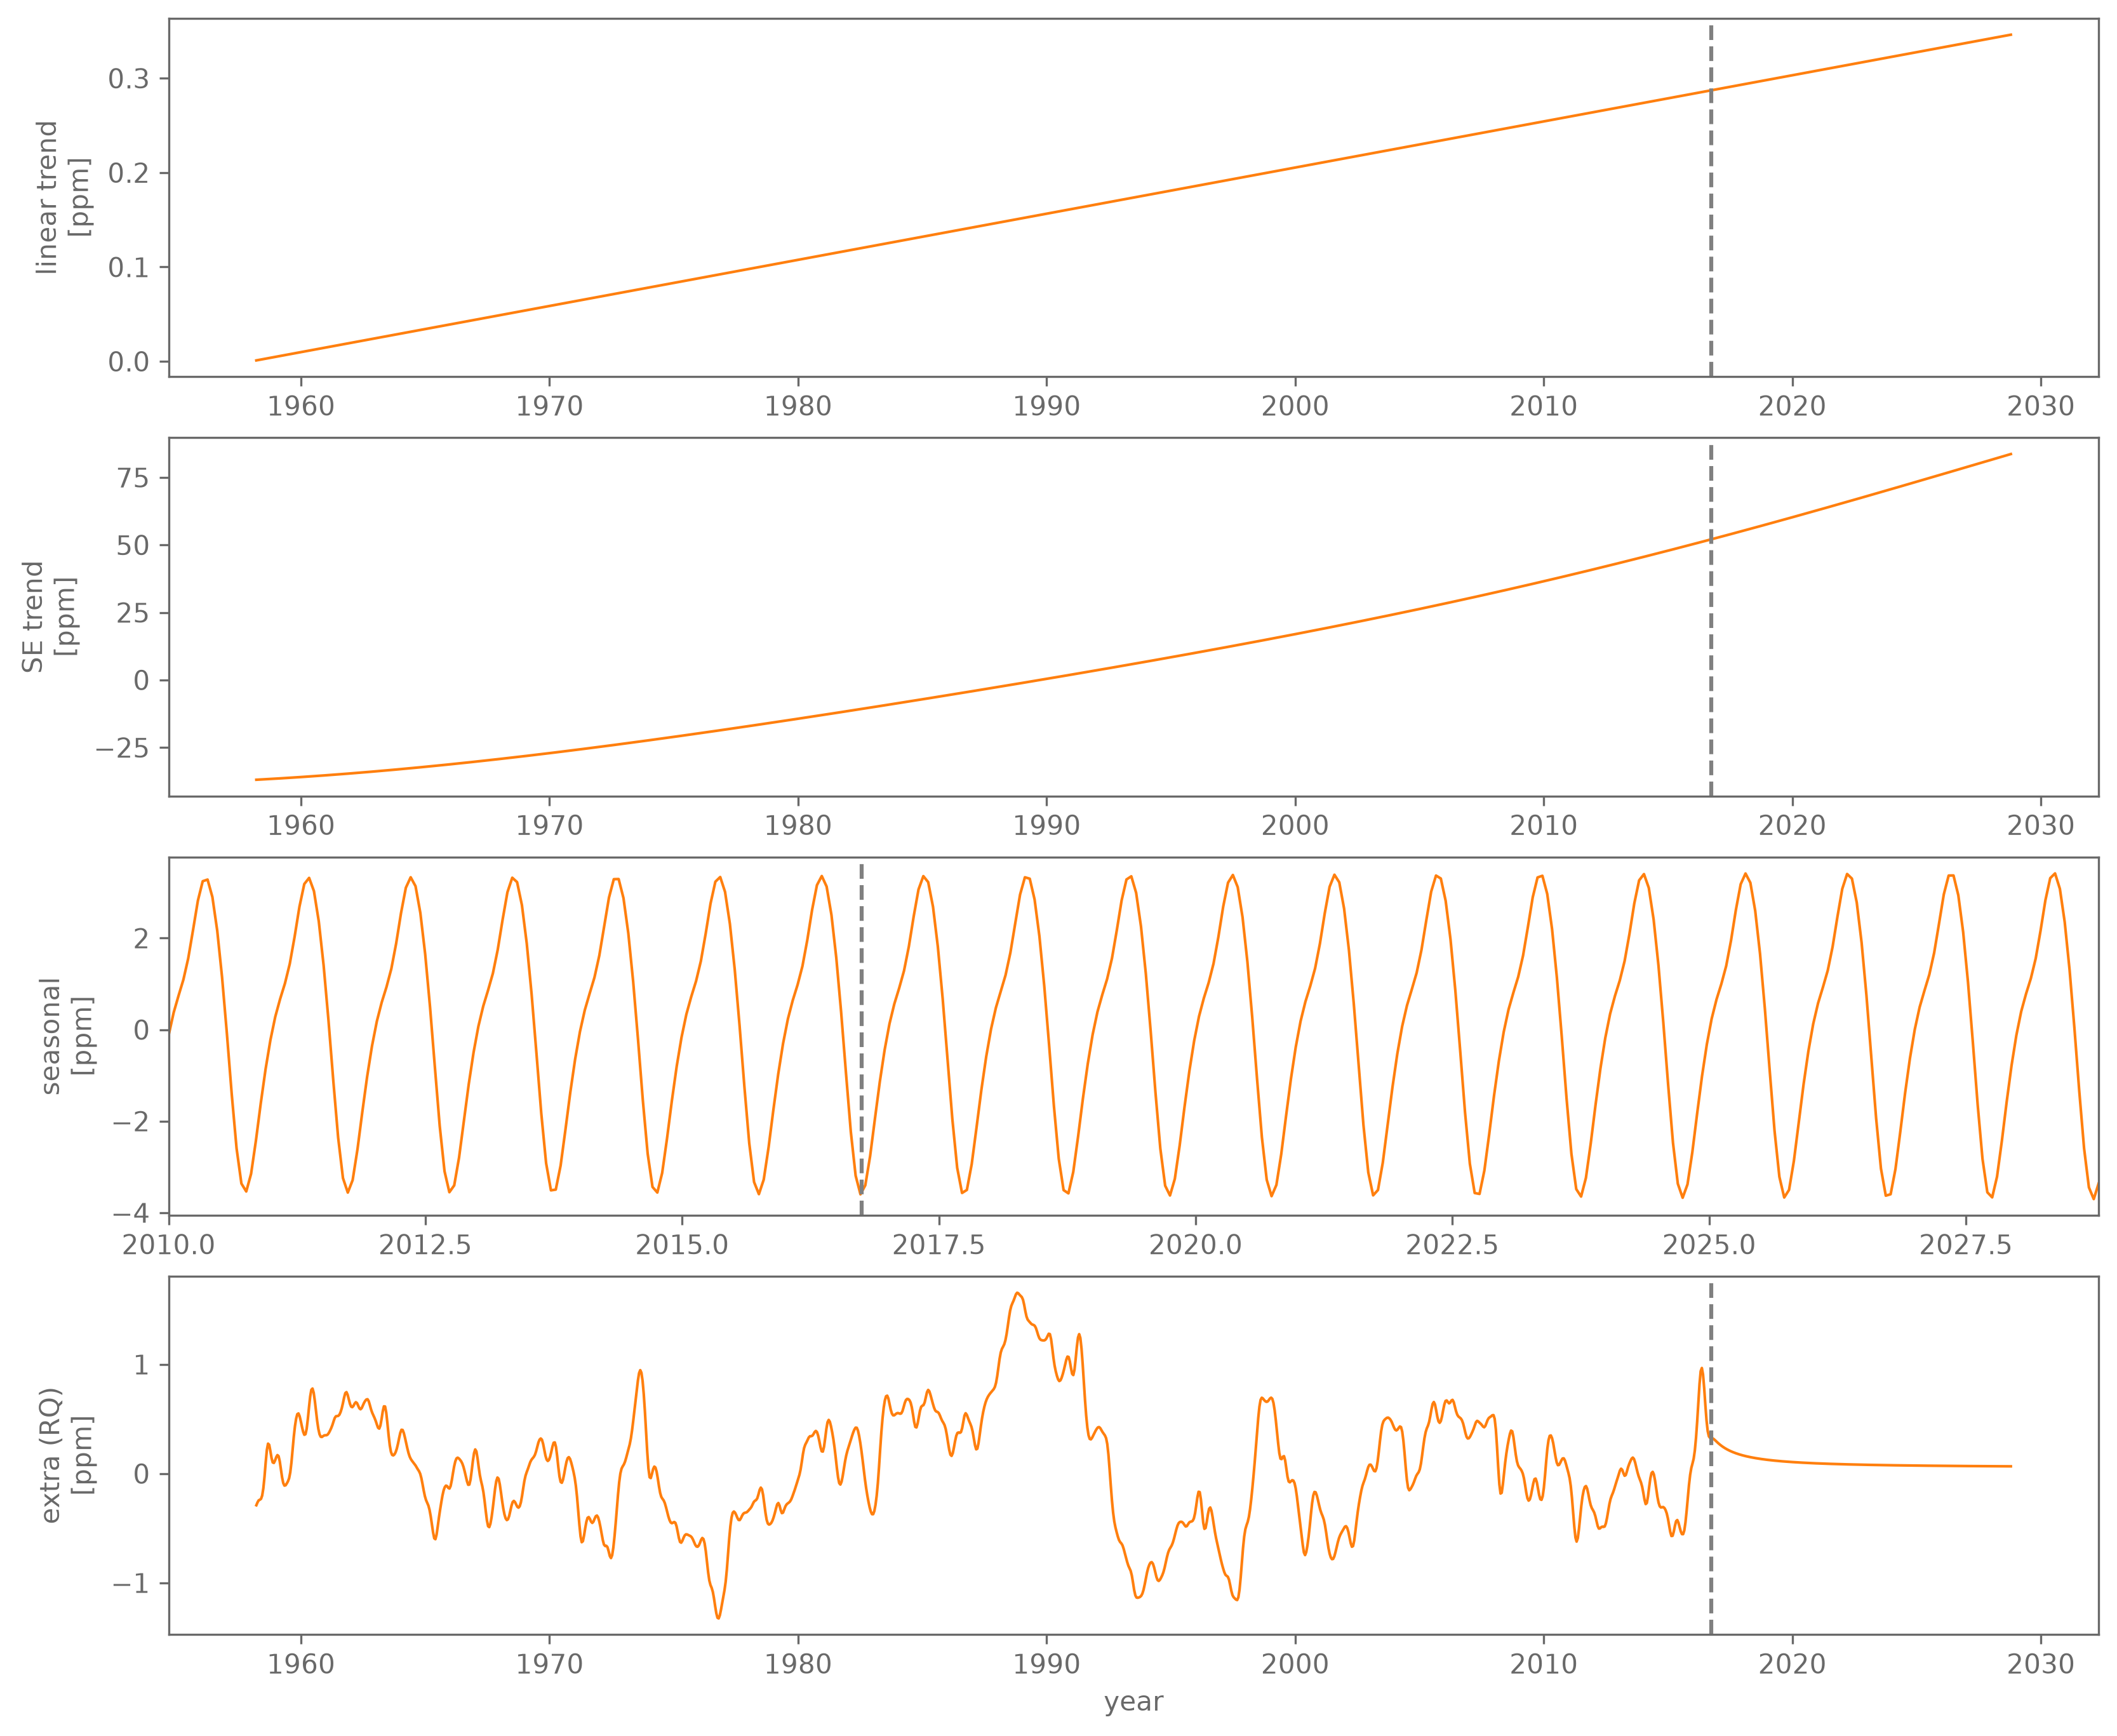

In [24]:
# the four terms of the best model's kernel, with its fitted parameters
best_components = {
    "linear trend": jnp.exp(2 * best_params["log_amp_linear"]) * kernels.DotProduct(),
    "SE trend": jnp.exp(2 * best_params["log_amp_trend"]) * kernels.ExpSquared(scale=jnp.exp(best_params["log_scale_trend"])),
    "seasonal": (jnp.exp(2 * best_params["log_amp_season"])
                 * kernels.ExpSquared(scale=jnp.exp(best_params["log_scale_decay"]))
                 * kernels.ExpSineSquared(scale=jnp.exp(best_params["log_period"]), gamma=jnp.exp(best_params["log_gamma"]))),
    "extra (RQ)": jnp.exp(2 * best_params["log_amplitude_extra"])
                  * kernels.RationalQuadratic(scale=jnp.exp(best_params["log_length_scale_extra"]), alpha=jnp.exp(best_params["log_shape_extra"])),
}

# condition on all the training data, but predict with one term of the kernel at a time (and no mean)
figure, axes = plt.subplots(len(best_components), 1, figsize=(11, 9), constrained_layout=True)
for axis, (name, component) in zip(axes, best_components.items()):
    prediction = best_gp.condition(co2_train, time_forecast, kernel=component, include_mean=False).gp
    axis.plot(time_forecast + 1958, prediction.loc, color="C1", lw=1)
    axis.axvline(2016.75, ls="--", color="gray")
    axis.set_ylabel(f"{name}\n[ppm]")
axes[2].set_xlim(2010, time_forecast.max() + 1958)   # zoom in, so the seasonal cycles are visible
axes[-1].set_xlabel("year");

*Solution note.* The squared-exponential trend carries almost all of the rise. The linear term adds only 0.35 ppm over 70 years: with its long length scale, the squared-exponential trend already keeps the forecast from reverting within the decade. The seasonal cycle is about $\pm 3.5$ ppm, lopsided, and keeps its shape. The extra (RQ) component holds wiggles of about $\pm 1$ ppm on scales of months to a year (for example 1988–1991 and 1993–1998). After 2016.75 it decays to zero within a year or two: with a short length scale, the forecast of that component soon falls back to its prior mean, zero.

*A bad forecast.* The Matérn-3/2 model beats the lecture model on evidence but has the worst held-out score. Its forecast shows why: after 2016.75 it falls further and further below the data, and by 2025 the data sit at the top edge of its 2-sigma band.

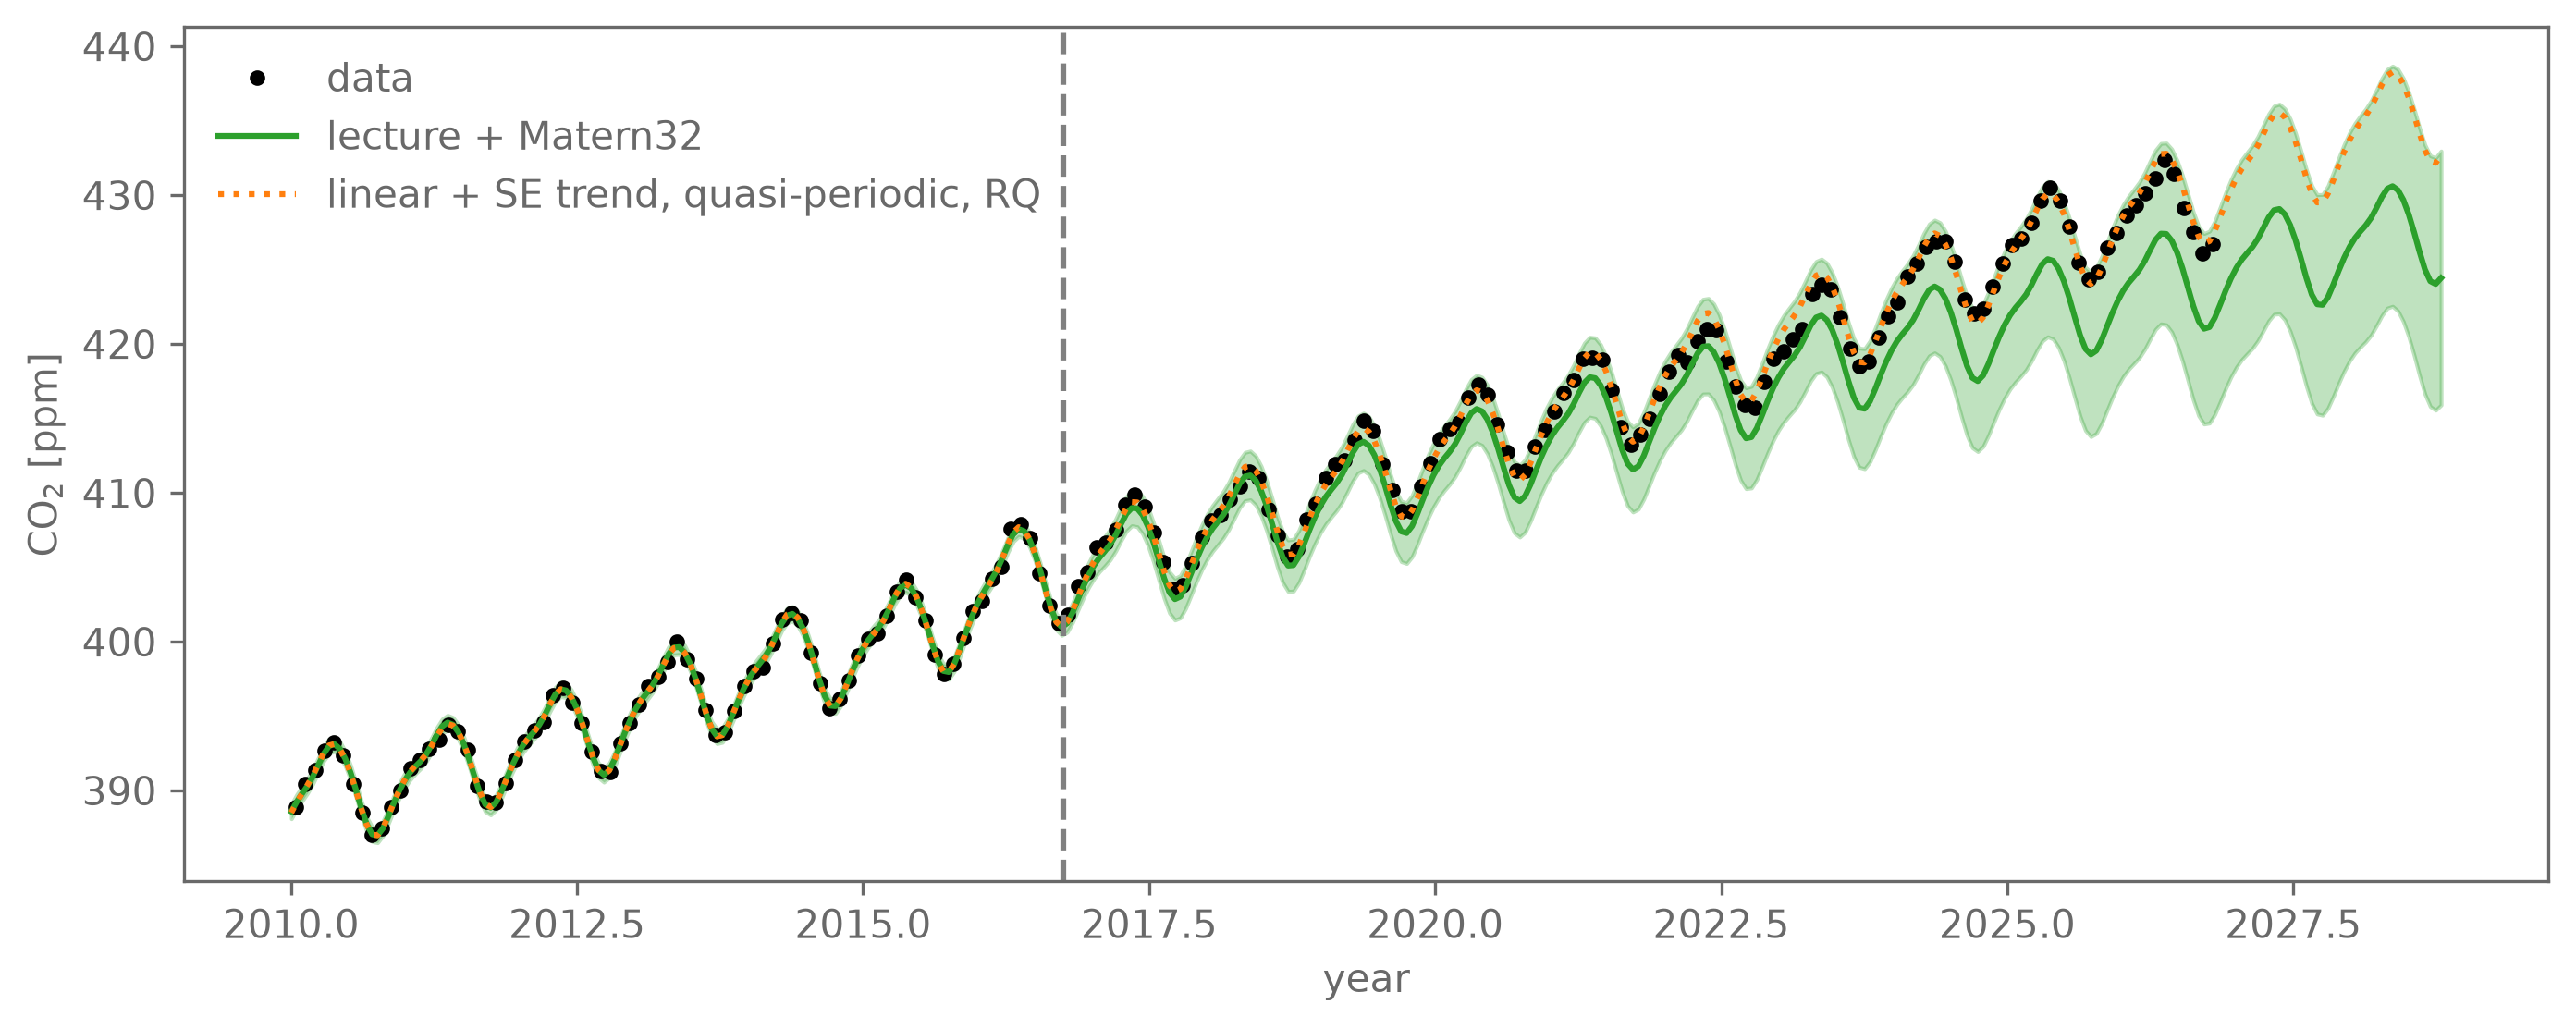

In [25]:
# a bad forecast: the Matern 3/2 model, from the training data to two years past the last data point
matern_label = "lecture + Matern32"
matern_params, matern_gp, _ = fits[matern_label]
matern_forecast = matern_gp.condition(co2_train, time_forecast).gp
matern_forecast_std = np.sqrt(matern_forecast.variance + np.exp(2 * float(matern_params["log_noise"])))

# plot from 2010 on: the data, the Matern model's forecast with a 2-sigma band, and the best model's
figure, axis = plt.subplots(figsize=(11, 4))
axis.plot(time_years[time_years + 1958 > 2010] + 1958, co2[time_years + 1958 > 2010], ".", color="k", label="data")
axis.plot(time_forecast[in_view] + 1958, matern_forecast.loc[in_view], color="C2", label=matern_label)
axis.fill_between(time_forecast[in_view] + 1958, (matern_forecast.loc - 2 * matern_forecast_std)[in_view],
                  (matern_forecast.loc + 2 * matern_forecast_std)[in_view], color="C2", alpha=0.3)
axis.plot(time_forecast[in_view] + 1958, forecast.loc[in_view], ":", color="C1", label=best_label)
axis.axvline(2016.75, ls="--", color="gray")
axis.set_xlabel("year"); axis.set_ylabel("CO$_2$ [ppm]"); axis.legend(loc="upper left");

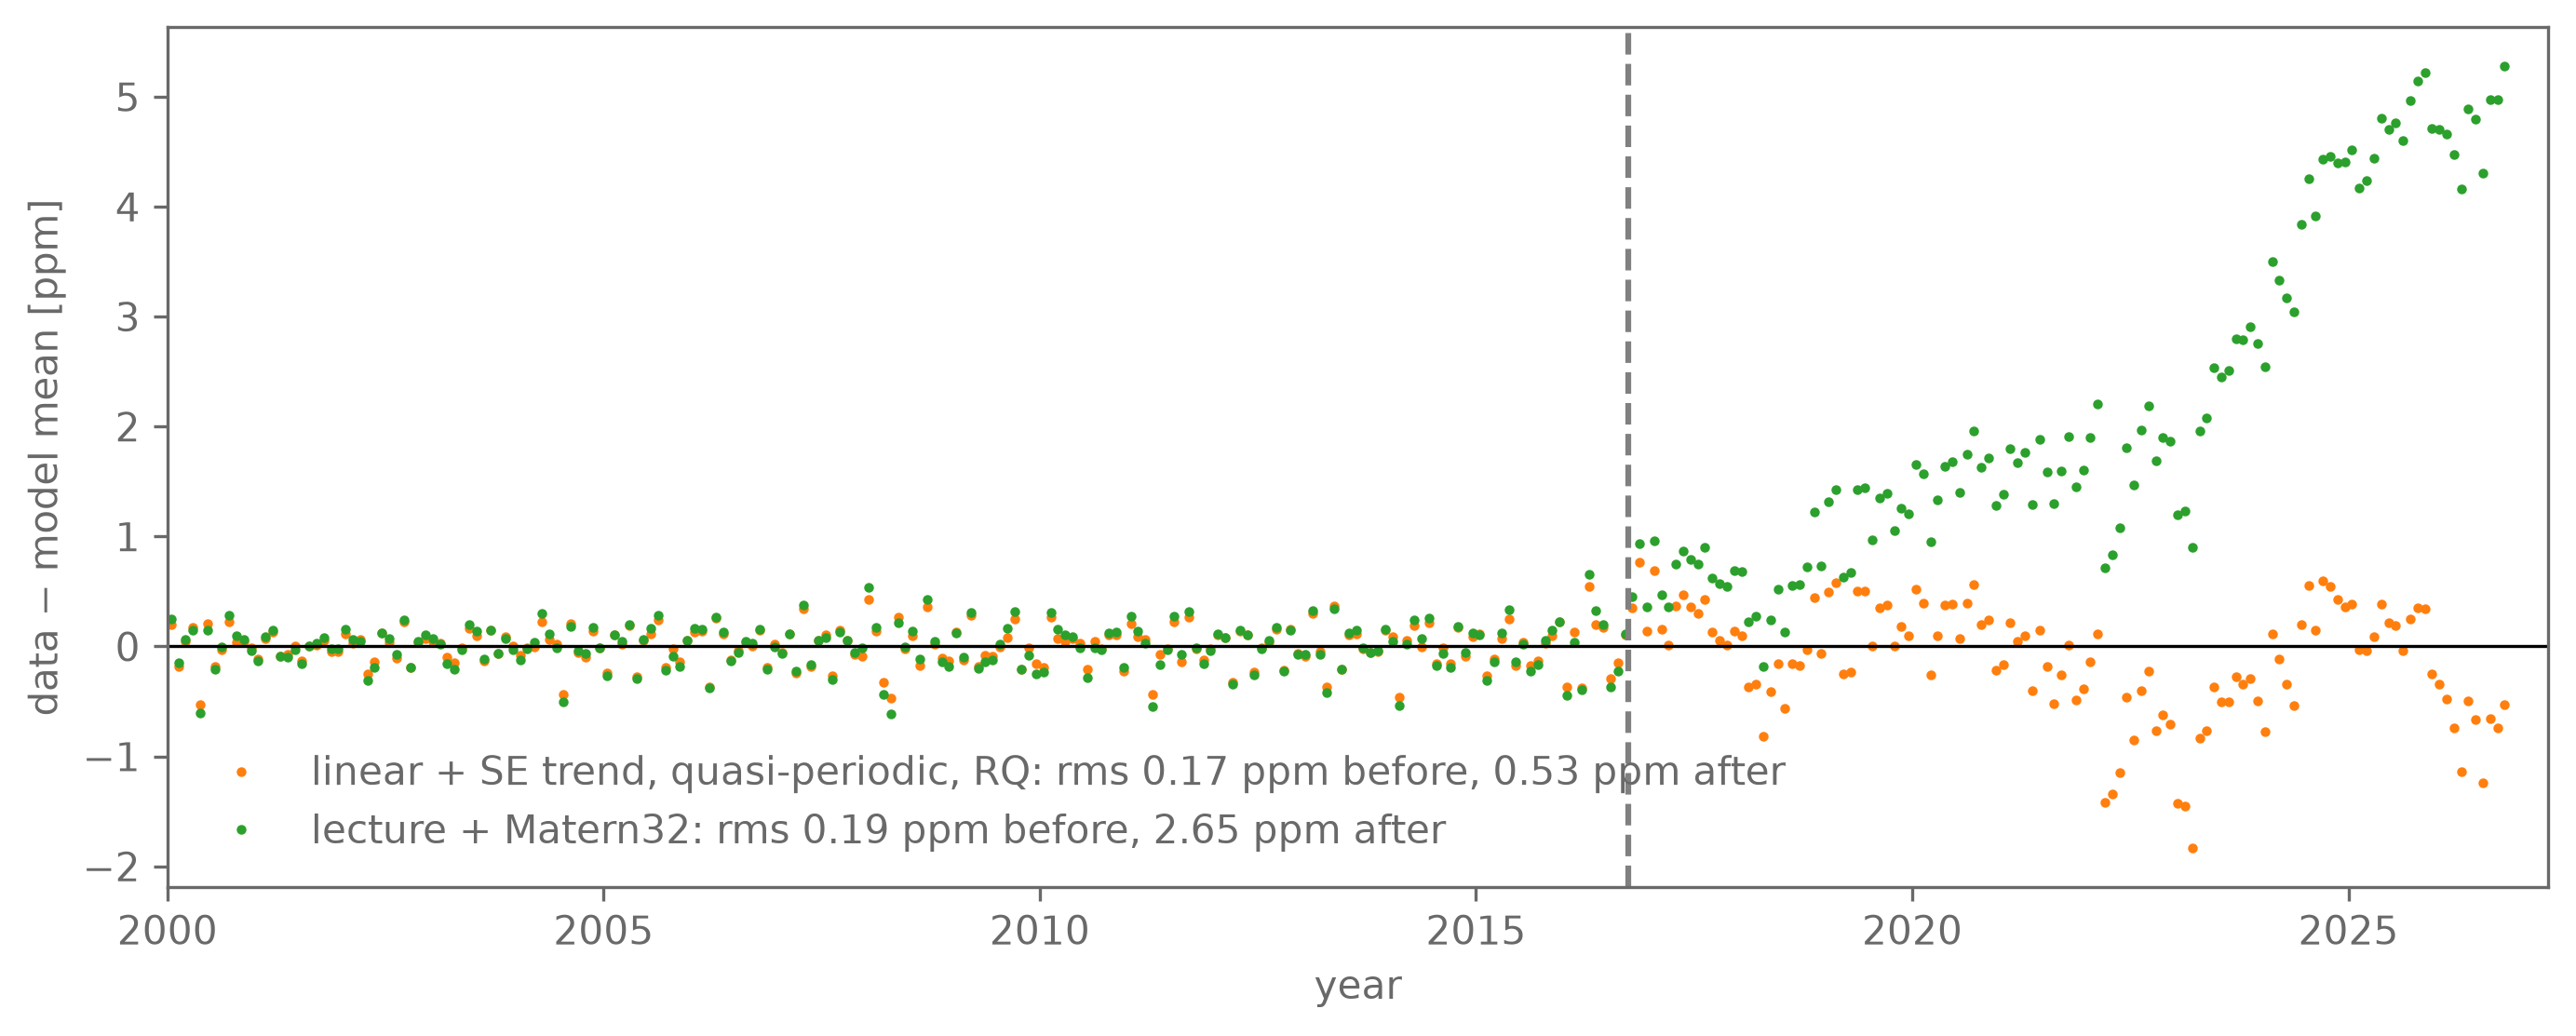

In [26]:
# residuals (data minus the model's mean) at every month: fitted before 2016.75, forecast after
figure, axis = plt.subplots(figsize=(11, 4))
for label, color in [(best_label, "C1"), (matern_label, "C2")]:
    params, gp, _ = fits[label]
    residuals = co2 - gp.condition(co2_train, time_years).gp.loc                     # (n_train + n_holdout,)
    # root-mean-square residual before and after the split
    rms_train, rms_holdout = np.sqrt(np.mean(residuals[is_train]**2)), np.sqrt(np.mean(residuals[~is_train]**2))
    axis.plot(time_years + 1958, residuals, ".", ms=3, color=color,
              label=f"{label}: rms {rms_train:.2f} ppm before, {rms_holdout:.2f} ppm after")
axis.axhline(0, color="k", lw=0.8); axis.axvline(2016.75, ls="--", color="gray")
axis.set_xlim(2000, time_years.max() + 1958 + 0.5)
axis.set_xlabel("year"); axis.set_ylabel("data $-$ model mean [ppm]"); axis.legend(loc="lower left");

*Solution note.* Before 2016.75, both models fit the training data to within the noise (rms 0.17 and 0.19 ppm). After 2016.75, the residuals of the best model stay below 2 ppm (rms 0.53 ppm), while the Matérn residuals grow to about 5 ppm (rms 2.65 ppm). So a good fit to the training data says little about a 10-year forecast. The held-out score tests that forecast directly; the evidence only tests one-step-ahead predictions within the training data.